# مرحله 05B پروژه FORCE
## Raw-Log Random Forest with Grouped Unseen-Well Cross-Validation

در این نوت‌بوک دو Random Forest تشخیصی ساخته می‌شوند:

```text
Raw-8 RF:
GR, NPHI, RHOB, DTC, RDEP, CALI, PEF, SP

Core-6 RF:
GR, NPHI, RHOB, DTC, RDEP, CALI
```

`Raw-8` مدل اصلی است. `Core-6` یک Sensitivity control است تا بررسی کنیم آیا اضافه‌شدن `PEF` و `SP` با Missingness زیاد واقعا Generalization را بهتر می‌کند یا مدل از Acquisition/Missingness pattern استفاده می‌کند.

## اصول قفل‌شده

- Grouped 5-fold validation براساس `WELL`
- هیچ چاه مشترکی بین Outer Training و Outer Validation
- Official Test کاملا قفل
- هیچ Feature engineering، Scaling یا Missingness indicator
- Median imputation فقط با Outer Training
- هیچ Hyperparameter tuning
- احتمال‌های خروجی در این مرحله **خام و Calibrated نشده‌اند**
- همان Hyperparameterهای Legacy Random Forest:

```text
n_estimators = 800
max_depth = 200
min_samples_split = 5
min_samples_leaf = 2
random_state = 142
class_weight = None
```

## خروجی‌ها

- پنج مدل و پنج Imputer برای هر Variant در اجرای Full
- OOF probabilities
- Pooled، Fold، Well و Class metrics
- Well-balanced metrics
- Missingness-stratified analysis
- Raw-8 vs Core-6 paired comparison
- Feature importance و Confusion matrices
- Gateهای کامل جلوگیری از Leakage

# Pilot و Full

Notebook به‌صورت پیش‌فرض روی:

```python
RUN_MODE = "pilot"
```

قرار دارد و Fold 1 را برای هر دو Variant با همان ۸۰۰ درخت اجرا می‌کند.

بعد از پاس‌شدن Pilot:

```python
RUN_MODE = "full"
```

را قرار بده. اجرای Full ده مدل می‌سازد:

```text
5 Raw-8 RF
5 Core-6 RF
```

با `SKIP_COMPLETED_FOLDS=True` اجرای قطع‌شده قابل ادامه است.

In [1]:
import sys, subprocess, importlib.util

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
    "pyarrow": "pyarrow",
}
for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package_name])
print("All required packages are available.")

All required packages are available.


In [2]:
from pathlib import Path
from collections import defaultdict
import gc, hashlib, json, platform, time, warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_fscore_support,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 300)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 250)

PROBABILITY_EPSILON = 1e-12
RANDOM_STATE = 142
np.random.seed(RANDOM_STATE)

def sha256_file(file_path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(file_path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

# 1. تنظیمات و مسیرها

In [3]:
RUN_MODE = "full"  # "pilot" or "full"

ACTIVE_OUTER_FOLDS = [1] if RUN_MODE == "pilot" else [1, 2, 3, 4, 5]

MODEL_VARIANTS = {
    "raw8": ["GR", "NPHI", "RHOB", "DTC", "RDEP", "CALI", "PEF", "SP"],
    "core6": ["GR", "NPHI", "RHOB", "DTC", "RDEP", "CALI"],
}
ACTIVE_MODEL_VARIANTS = ["raw8", "core6"]

RF_HYPERPARAMETERS = {
    "n_estimators": 800,
    "max_depth": 200,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "random_state": 142,
    "n_jobs": -1,
    "class_weight": None,
    "bootstrap": True,
    "criterion": "gini",
}

SKIP_COMPLETED_FOLDS = True
JOBLIB_COMPRESSION = 1
MAX_ROWS_FOR_PLOTS = 200_000

# Portable project paths (independent of machine-specific Desktop folders).
import os

def _find_stratashift_root():
    start = Path(os.environ.get("STRATASHIFT_REPO_ROOT", Path.cwd())).expanduser().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks" / "interventions").is_dir() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError(
        "StrataShift repository root not found. Open Jupyter from inside the repo "
        "or set STRATASHIFT_REPO_ROOT to its absolute path."
    )

REPO_ROOT = _find_stratashift_root()
TRAIN_PATH = Path(os.environ.get(
    "STRATASHIFT_TRAIN_CSV", str(REPO_ROOT / "data" / "raw" / "train.csv")
)).expanduser().resolve()
PROJECT_ROOT = Path(os.environ.get(
    "STRATASHIFT_ARTIFACT_ROOT", str(REPO_ROOT / "artifacts")
)).expanduser().resolve()

STAGE_01_DIR = PROJECT_ROOT / "01_clean_splits_support"
FOLD_ASSIGNMENT_PATH = STAGE_01_DIR / "10_grouped_5fold_well_assignment.csv"

STAGE_05A_DIR = PROJECT_ROOT / "05A_raw_log_feature_contract" / "full"
PRIMARY_CONTRACT_PATH = STAGE_05A_DIR / "10_primary_raw_feature_contract.json"
PREPROCESSING_POLICY_PATH = STAGE_05A_DIR / "12_fold_safe_preprocessing_policy.json"
STAGE_05A_GATE_PATH = STAGE_05A_DIR / "13_raw_feature_contract_gate.json"
STAGE_05A_HASH_PATH = STAGE_05A_DIR / "15_input_file_hashes.json"

OUTPUT_DIR = PROJECT_ROOT / "05B_raw_log_RF_grouped_well_CV" / RUN_MODE
MODEL_DIR = OUTPUT_DIR / "models"
FOLD_OOF_DIR = OUTPUT_DIR / "fold_oof"
CONFUSION_DIR = OUTPUT_DIR / "confusion_matrices"
PLOT_DIR = OUTPUT_DIR / "plots"

for directory in [OUTPUT_DIR, MODEL_DIR, FOLD_OOF_DIR, CONFUSION_DIR, PLOT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SENTINEL_VALUES = {"SP": [-999.0]}
POSITIVE_ONLY_FEATURES = {"RDEP"}

required_paths = [
    TRAIN_PATH,
    FOLD_ASSIGNMENT_PATH,
    PRIMARY_CONTRACT_PATH,
    PREPROCESSING_POLICY_PATH,
    STAGE_05A_GATE_PATH,
    STAGE_05A_HASH_PATH,
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError("Required inputs are missing:\n" + "\n".join(missing_paths))

print("RUN_MODE:", RUN_MODE)
print("Outer folds:", ACTIVE_OUTER_FOLDS)
print("Variants:", ACTIVE_MODEL_VARIANTS)
print("Output:", OUTPUT_DIR)

RUN_MODE: full
Outer folds: [1, 2, 3, 4, 5]
Variants: ['raw8', 'core6']
Output: ${STRATASHIFT_ARTIFACT_ROOT}/05B_raw_log_RF_grouped_well_CV/full


# 2. Audit قرارداد 05A و Hash ورودی‌ها

In [4]:
with open(PRIMARY_CONTRACT_PATH, "r", encoding="utf-8") as file:
    primary_contract = json.load(file)
with open(PREPROCESSING_POLICY_PATH, "r", encoding="utf-8") as file:
    preprocessing_policy = json.load(file)
with open(STAGE_05A_GATE_PATH, "r", encoding="utf-8") as file:
    stage_05a_gate = json.load(file)
with open(STAGE_05A_HASH_PATH, "r", encoding="utf-8") as file:
    stage_05a_hashes = json.load(file)

current_hashes = {
    "train_csv_sha256": sha256_file(TRAIN_PATH),
    "fold_assignment_sha256": sha256_file(FOLD_ASSIGNMENT_PATH),
}

CONTRACT_AUDIT = {
    "stage_05a_passed": bool(stage_05a_gate.get("overall_raw_feature_contract_passed", False)),
    "official_test_unused_in_05A": bool(stage_05a_gate.get("official_test_unused", False)),
    "raw8_matches_primary_contract": MODEL_VARIANTS["raw8"] == primary_contract.get("input_features", []),
    "core6_is_strict_subset": set(MODEL_VARIANTS["core6"]) < set(MODEL_VARIANTS["raw8"]),
    "imputer_fit_scope_is_outer_training": preprocessing_policy.get("fit_scope") == "outer-training rows only",
    "train_hash_matches_05A": current_hashes["train_csv_sha256"] == stage_05a_hashes["train_csv_sha256"],
    "fold_hash_matches_05A": current_hashes["fold_assignment_sha256"] == stage_05a_hashes["fold_assignment_sha256"],
}
print(json.dumps(CONTRACT_AUDIT, indent=2))
if not all(CONTRACT_AUDIT.values()):
    raise RuntimeError("05A contract/hash audit failed.")

{
  "stage_05a_passed": true,
  "official_test_unused_in_05A": true,
  "raw8_matches_primary_contract": true,
  "core6_is_strict_subset": true,
  "imputer_fit_scope_is_outer_training": true,
  "train_hash_matches_05A": true,
  "fold_hash_matches_05A": true
}


# 3. بارگذاری Train و Fold assignment

In [5]:
def detect_csv_format(file_path, num_lines=5):
    for encoding in ["utf-8", "latin1", "iso-8859-1", "cp1252"]:
        try:
            with open(file_path, "r", encoding=encoding) as file:
                lines = [file.readline() for _ in range(num_lines)]
            if any("," in line for line in lines):
                sep = ","
            elif any(";" in line for line in lines):
                sep = ";"
            elif any("\t" in line for line in lines):
                sep = "\t"
            else:
                sep = ","
            return {"sep": sep, "encoding": encoding}
        except UnicodeDecodeError:
            continue
    return {"sep": ",", "encoding": "utf-8"}

csv_format = detect_csv_format(TRAIN_PATH)
train_raw = pd.read_csv(
    TRAIN_PATH,
    sep=csv_format["sep"],
    encoding=csv_format["encoding"],
    low_memory=False,
)
train_raw["ORIGINAL_ROW_ID"] = np.arange(len(train_raw), dtype=np.int64)

fold_assignment_raw = pd.read_csv(FOLD_ASSIGNMENT_PATH)
well_column = [c for c in fold_assignment_raw.columns if c.upper() == "WELL"][0]
fold_column = [
    c for c in fold_assignment_raw.columns
    if "FOLD" in c.upper() and "SCORE" not in c.upper()
][0]

fold_assignment = (
    fold_assignment_raw[[well_column, fold_column]]
    .rename(columns={well_column: "WELL", fold_column: "GROUP_FOLD"})
    .drop_duplicates(subset=["WELL"])
)
fold_assignment["GROUP_FOLD"] = pd.to_numeric(
    fold_assignment["GROUP_FOLD"], errors="raise"
).astype(int)

train_raw["GROUP_FOLD"] = train_raw["WELL"].map(
    dict(zip(fold_assignment["WELL"], fold_assignment["GROUP_FOLD"]))
)
if train_raw["GROUP_FOLD"].isna().any():
    missing_wells = train_raw.loc[train_raw["GROUP_FOLD"].isna(), "WELL"].unique().tolist()
    raise RuntimeError(f"Wells without fold assignment: {missing_wells[:20]}")
train_raw["GROUP_FOLD"] = train_raw["GROUP_FOLD"].astype(int)

print("Train shape:", train_raw.shape)
print("Wells:", train_raw["WELL"].nunique())
print("Folds:", sorted(train_raw["GROUP_FOLD"].unique().tolist()))

Train shape: (1170511, 31)
Wells: 98
Folds: [1, 2, 3, 4, 5]


# 4. Target و کلاس‌ها

In [6]:
TARGET_COLUMN = "FORCE_2020_LITHOFACIES_LITHOLOGY"

GLOBAL_CLASS_CODES = np.array(
    [30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000],
    dtype=np.int64,
)
LITHOLOGY_NAMES = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}
CLASS_CODE_TO_INDEX = {int(code): i for i, code in enumerate(GLOBAL_CLASS_CODES)}

train_raw["LITHOLOGY_CODE"] = pd.to_numeric(train_raw[TARGET_COLUMN], errors="coerce")
if train_raw["LITHOLOGY_CODE"].isna().any():
    raise ValueError("Missing/non-numeric labels exist.")
train_raw["LITHOLOGY_CODE"] = train_raw["LITHOLOGY_CODE"].astype(np.int64)

unknown_codes = sorted(set(train_raw["LITHOLOGY_CODE"].unique()) - set(GLOBAL_CLASS_CODES))
if unknown_codes:
    raise ValueError(f"Unknown class codes: {unknown_codes}")

train_raw["LITHOLOGY_NAME"] = train_raw["LITHOLOGY_CODE"].map(LITHOLOGY_NAMES)

global_class_support = (
    train_raw.groupby(["LITHOLOGY_CODE", "LITHOLOGY_NAME"], as_index=False)
    .agg(rows=("WELL", "size"), wells=("WELL", "nunique"))
)
display(global_class_support)

,LITHOLOGY_CODE,LITHOLOGY_NAME,rows,wells
0,30000,Sandstone,168937,98
1,65000,Shale,720803,98
2,65030,Sandstone/Shale,150455,97
3,70000,Limestone,56320,94
4,70032,Chalk,10513,11
5,74000,Dolomite,1688,37
6,80000,Marl,33329,73
7,86000,Anhydrite,1085,6
8,88000,Halite,8213,3
9,90000,Coal,3820,51


# 5. Cleaning و Missingness audit

In [7]:
def clean_feature_series(dataframe, feature):
    values = pd.to_numeric(dataframe[feature], errors="coerce").astype(float)

    sentinel_mask = np.zeros(len(values), dtype=bool)
    for sentinel in SENTINEL_VALUES.get(feature, []):
        sentinel_mask |= np.isclose(
            values.to_numpy(dtype=float),
            sentinel,
            rtol=0.0,
            atol=1e-12,
            equal_nan=False,
        )
    values.loc[sentinel_mask] = np.nan

    nonfinite_mask = ~np.isfinite(values.to_numpy(dtype=float))
    values.loc[nonfinite_mask] = np.nan

    nonpositive_mask = np.zeros(len(values), dtype=bool)
    if feature in POSITIVE_ONLY_FEATURES:
        nonpositive_mask = values.notna().to_numpy() & (values.to_numpy(dtype=float) <= 0)
        values.loc[nonpositive_mask] = np.nan

    return {
        "values": values,
        "sentinel_mask": sentinel_mask,
        "nonfinite_mask": nonfinite_mask,
        "nonpositive_mask": nonpositive_mask,
    }

all_required_features = sorted(set(sum(MODEL_VARIANTS.values(), [])))
missing_features = [f for f in all_required_features if f not in train_raw.columns]
if missing_features:
    raise KeyError(f"Missing features: {missing_features}")

clean_feature_matrix = pd.DataFrame(index=train_raw.index)
cleaning_rows = []

for feature in all_required_features:
    cleaned = clean_feature_series(train_raw, feature)
    clean_feature_matrix[feature] = cleaned["values"].astype(np.float32)
    cleaning_rows.append({
        "feature": feature,
        "rows": len(train_raw),
        "observed_rows_after_cleaning": int(cleaned["values"].notna().sum()),
        "missing_rate_after_cleaning": float(cleaned["values"].isna().mean()),
        "sentinel_rows_removed": int(cleaned["sentinel_mask"].sum()),
        "nonfinite_rows_removed": int(cleaned["nonfinite_mask"].sum()),
        "nonpositive_rows_removed": int(cleaned["nonpositive_mask"].sum()),
    })

cleaning_audit = pd.DataFrame(cleaning_rows)

raw8_missing = clean_feature_matrix[MODEL_VARIANTS["raw8"]].isna()
row_missingness = pd.DataFrame({
    "ORIGINAL_ROW_ID": train_raw["ORIGINAL_ROW_ID"].to_numpy(),
    "missing_count_raw8": raw8_missing.sum(axis=1).astype(np.int16),
    "all_8_observed": ~raw8_missing.any(axis=1),
    "PEF_missing": raw8_missing["PEF"],
    "SP_missing": raw8_missing["SP"],
})
row_missingness["PEF_SP_availability_group"] = np.select(
    [
        ~row_missingness["PEF_missing"] & ~row_missingness["SP_missing"],
        row_missingness["PEF_missing"] & ~row_missingness["SP_missing"],
        ~row_missingness["PEF_missing"] & row_missingness["SP_missing"],
        row_missingness["PEF_missing"] & row_missingness["SP_missing"],
    ],
    [
        "PEF_observed__SP_observed",
        "PEF_missing__SP_observed",
        "PEF_observed__SP_missing",
        "PEF_missing__SP_missing",
    ],
    default="unknown",
)
row_missingness["missing_count_group"] = pd.cut(
    row_missingness["missing_count_raw8"],
    bins=[-0.5, 0.5, 1.5, 2.5, 8.5],
    labels=["0_missing", "1_missing", "2_missing", "3plus_missing"],
).astype(str)

display(cleaning_audit)
display(row_missingness.head())

,feature,rows,observed_rows_after_cleaning,missing_rate_after_cleaning,sentinel_rows_removed,nonfinite_rows_removed,nonpositive_rows_removed
0,CALI,1170511,1082634,0.075076,0,87877,0
1,DTC,1170511,1089648,0.069084,0,80863,0
2,GR,1170511,1170511,0.000000,0,0,0
3,NPHI,1170511,765409,0.346090,0,405102,0
4,PEF,1170511,671692,0.426155,0,498819,0
5,RDEP,1170511,1159496,0.009410,0,11015,0
6,RHOB,1170511,1009242,0.137777,0,161269,0
7,SP,1170511,863845,0.261993,402,306666,0


,ORIGINAL_ROW_ID,missing_count_raw8,all_8_observed,PEF_missing,SP_missing,PEF_SP_availability_group,missing_count_group
0,0,1,False,False,False,PEF_observed__SP_observed,1_missing
1,1,1,False,False,False,PEF_observed__SP_observed,1_missing
2,2,1,False,False,False,PEF_observed__SP_observed,1_missing
3,3,1,False,False,False,PEF_observed__SP_observed,1_missing
4,4,1,False,False,False,PEF_observed__SP_observed,1_missing


# 6. Metric helperها

In [8]:
def align_probabilities(local_probabilities, local_classes):
    local_probabilities = np.asarray(local_probabilities, dtype=np.float64)
    aligned = np.zeros(
        (local_probabilities.shape[0], len(GLOBAL_CLASS_CODES)),
        dtype=np.float64,
    )
    for local_index, class_code in enumerate(local_classes):
        aligned[:, CLASS_CODE_TO_INDEX[int(class_code)]] = local_probabilities[:, local_index]
    row_sums = aligned.sum(axis=1, keepdims=True)
    if np.any(row_sums <= 0):
        raise RuntimeError("Probability row with non-positive sum.")
    return aligned / row_sums

def row_probability_outputs(y_true, probabilities):
    y_true = np.asarray(y_true, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    true_indices = np.array([CLASS_CODE_TO_INDEX[int(code)] for code in y_true])
    true_probability = probabilities[np.arange(len(y_true)), true_indices]
    row_loss = -np.log(np.clip(true_probability, PROBABILITY_EPSILON, 1.0))
    predicted = GLOBAL_CLASS_CODES[np.argmax(probabilities, axis=1)]
    return {
        "true_class_probability": true_probability,
        "row_log_loss": row_loss,
        "predicted_codes": predicted,
        "correct": predicted == y_true,
    }

def multiclass_brier(y_true, probabilities):
    y_true = np.asarray(y_true, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    one_hot = np.zeros_like(probabilities)
    true_indices = np.array([CLASS_CODE_TO_INDEX[int(code)] for code in y_true])
    one_hot[np.arange(len(y_true)), true_indices] = 1.0
    return float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1)))

def multiclass_metrics(y_true, probabilities):
    row_outputs = row_probability_outputs(y_true, probabilities)
    predicted = row_outputs["predicted_codes"]
    return {
        "rows": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, predicted)),
        "macro_f1": float(f1_score(
            y_true,
            predicted,
            labels=GLOBAL_CLASS_CODES,
            average="macro",
            zero_division=0,
        )),
        "weighted_f1": float(f1_score(
            y_true,
            predicted,
            labels=GLOBAL_CLASS_CODES,
            average="weighted",
            zero_division=0,
        )),
        "log_loss": float(log_loss(y_true, probabilities, labels=GLOBAL_CLASS_CODES)),
        "multiclass_brier": multiclass_brier(y_true, probabilities),
        "mean_true_class_probability": float(np.mean(row_outputs["true_class_probability"])),
    }

PROBABILITY_COLUMNS = [f"prob_{code}" for code in GLOBAL_CLASS_CODES]

def metrics_from_oof(group_df):
    y_true = group_df["true_code"].to_numpy(dtype=np.int64)
    probabilities = group_df[PROBABILITY_COLUMNS].to_numpy(dtype=np.float64)
    predicted = group_df["predicted_code"].to_numpy(dtype=np.int64)
    present_classes = np.unique(y_true)
    return {
        "rows": int(len(group_df)),
        "classes_present": int(len(present_classes)),
        "accuracy": float(accuracy_score(y_true, predicted)),
        "macro_f1_present_classes": float(f1_score(
            y_true,
            predicted,
            labels=present_classes,
            average="macro",
            zero_division=0,
        )),
        "log_loss": float(log_loss(y_true, probabilities, labels=GLOBAL_CLASS_CODES)),
        "multiclass_brier": multiclass_brier(y_true, probabilities),
        "mean_true_class_probability": float(group_df["true_class_probability"].mean()),
    }

# 7. آموزش Foldها و ذخیره مدل‌های Frozen

In [9]:
fold_metric_rows = []
fold_audit_rows = []
imputer_rows = []
importance_rows = []
artifact_rows = []
oof_frames = defaultdict(list)

for model_variant in ACTIVE_MODEL_VARIANTS:
    feature_list = MODEL_VARIANTS[model_variant]
    print("\n" + "=" * 90)
    print("MODEL:", model_variant, "| FEATURES:", feature_list)

    for outer_fold in ACTIVE_OUTER_FOLDS:
        print("\n" + "-" * 90)
        print(f"{model_variant} | outer fold {outer_fold}")

        prefix = f"{model_variant}__outer_fold_{outer_fold}"
        model_path = MODEL_DIR / f"{prefix}__RF.joblib"
        imputer_path = MODEL_DIR / f"{prefix}__median_imputer.joblib"
        metadata_path = MODEL_DIR / f"{prefix}__metadata.json"
        fold_oof_path = FOLD_OOF_DIR / f"{prefix}__OOF.parquet"

        cache_complete = all(path.exists() for path in [
            model_path, imputer_path, metadata_path, fold_oof_path
        ])

        if SKIP_COMPLETED_FOLDS and cache_complete:
            print("Loading cached completed fold...")
            fold_oof = pd.read_parquet(fold_oof_path)
            with open(metadata_path, "r", encoding="utf-8") as file:
                metadata = json.load(file)
            if not metadata.get("fold_gate_passed", False):
                raise RuntimeError(f"Cached fold gate failed: {prefix}")

            oof_frames[model_variant].append(fold_oof)
            fold_metric_rows.append(metadata["fold_metrics"])
            fold_audit_rows.append(metadata["fold_audit"])
            imputer_rows.extend(metadata["imputer_medians"])
            importance_rows.extend(metadata["feature_importances"])

            for artifact_type, path in [
                ("random_forest", model_path),
                ("median_imputer", imputer_path),
                ("fold_oof", fold_oof_path),
            ]:
                artifact_rows.append({
                    "model_variant": model_variant,
                    "outer_fold": outer_fold,
                    "artifact_type": artifact_type,
                    "path": str(path),
                    "sha256": sha256_file(path),
                    "status": "loaded_from_cache",
                })
            continue

        start_time = time.time()
        validation_mask = (train_raw["GROUP_FOLD"] == outer_fold).to_numpy()
        training_mask = ~validation_mask

        training_wells = set(train_raw.loc[training_mask, "WELL"].unique())
        validation_wells = set(train_raw.loc[validation_mask, "WELL"].unique())
        well_overlap = training_wells & validation_wells
        if well_overlap:
            raise RuntimeError(f"WELL leakage: {sorted(well_overlap)}")

        X_train_raw = clean_feature_matrix.loc[training_mask, feature_list].to_numpy(dtype=np.float32)
        X_validation_raw = clean_feature_matrix.loc[validation_mask, feature_list].to_numpy(dtype=np.float32)
        y_train = train_raw.loc[training_mask, "LITHOLOGY_CODE"].to_numpy(dtype=np.int64)
        y_validation = train_raw.loc[validation_mask, "LITHOLOGY_CODE"].to_numpy(dtype=np.int64)

        training_classes = sorted(np.unique(y_train).tolist())
        validation_classes = sorted(np.unique(y_validation).tolist())
        validation_only_classes = sorted(set(validation_classes) - set(training_classes))

        imputer = SimpleImputer(strategy="median")
        X_train = imputer.fit_transform(X_train_raw).astype(np.float32, copy=False)
        X_validation = imputer.transform(X_validation_raw).astype(np.float32, copy=False)

        if not np.isfinite(X_train).all() or not np.isfinite(X_validation).all():
            raise RuntimeError(f"Non-finite matrix after imputation: {prefix}")

        current_imputer_rows = []
        for index, feature in enumerate(feature_list):
            row = {
                "model_variant": model_variant,
                "outer_fold": outer_fold,
                "feature": feature,
                "outer_training_median": float(imputer.statistics_[index]),
                "outer_training_missing_rows": int(np.isnan(X_train_raw[:, index]).sum()),
                "outer_validation_missing_rows": int(np.isnan(X_validation_raw[:, index]).sum()),
            }
            current_imputer_rows.append(row)
            imputer_rows.append(row)

        model = RandomForestClassifier(**RF_HYPERPARAMETERS)
        model.fit(X_train, y_train)

        probabilities = align_probabilities(
            model.predict_proba(X_validation),
            model.classes_,
        )
        row_outputs = row_probability_outputs(y_validation, probabilities)
        fold_metrics = multiclass_metrics(y_validation, probabilities)
        fold_metrics.update({
            "model_variant": model_variant,
            "outer_fold": outer_fold,
            "training_rows": int(training_mask.sum()),
            "validation_rows": int(validation_mask.sum()),
            "training_wells": int(len(training_wells)),
            "validation_wells": int(len(validation_wells)),
            "training_classes": int(len(training_classes)),
            "validation_classes": int(len(validation_classes)),
            "validation_only_class_count": int(len(validation_only_classes)),
            "validation_only_classes": "|".join(str(code) for code in validation_only_classes),
            "fit_predict_seconds": float(time.time() - start_time),
        })
        fold_metric_rows.append(fold_metrics)

        current_importance_rows = []
        for feature, importance in zip(feature_list, model.feature_importances_):
            row = {
                "model_variant": model_variant,
                "outer_fold": outer_fold,
                "feature": feature,
                "importance": float(importance),
            }
            current_importance_rows.append(row)
            importance_rows.append(row)

        validation_indices = np.where(validation_mask)[0]
        fold_oof = (
            train_raw.loc[
                validation_mask,
                [
                    "ORIGINAL_ROW_ID",
                    "WELL",
                    "DEPTH_MD",
                    "GROUP_FOLD",
                    "LITHOLOGY_CODE",
                    "LITHOLOGY_NAME",
                ],
            ]
            .rename(columns={
                "GROUP_FOLD": "outer_fold",
                "LITHOLOGY_CODE": "true_code",
                "LITHOLOGY_NAME": "true_name",
            })
            .copy()
        )
        fold_oof["model_variant"] = model_variant
        fold_oof["predicted_code"] = row_outputs["predicted_codes"].astype(np.int64)
        fold_oof["predicted_name"] = fold_oof["predicted_code"].map(LITHOLOGY_NAMES)
        fold_oof["correct"] = row_outputs["correct"]
        fold_oof["true_class_probability"] = row_outputs["true_class_probability"].astype(np.float32)
        fold_oof["row_log_loss"] = row_outputs["row_log_loss"].astype(np.float32)

        for class_index, class_code in enumerate(GLOBAL_CLASS_CODES):
            fold_oof[f"prob_{class_code}"] = probabilities[:, class_index].astype(np.float32)

        fold_oof = fold_oof.merge(
            row_missingness.iloc[validation_indices],
            on="ORIGINAL_ROW_ID",
            how="left",
            validate="one_to_one",
        )

        probability_matrix = fold_oof[PROBABILITY_COLUMNS].to_numpy(dtype=np.float64)
        fold_audit = {
            "model_variant": model_variant,
            "outer_fold": outer_fold,
            "train_validation_well_overlap_count": int(len(well_overlap)),
            "train_validation_wells_disjoint": len(well_overlap) == 0,
            "imputer_fit_on_outer_training_only": True,
            "model_fit_on_outer_training_only": True,
            "feature_order_exact": feature_list == MODEL_VARIANTS[model_variant],
            "validation_row_count_matches": len(fold_oof) == int(validation_mask.sum()),
            "validation_row_ids_unique": not fold_oof["ORIGINAL_ROW_ID"].duplicated().any(),
            "probability_rows_sum_to_one": bool(np.allclose(
                probability_matrix.sum(axis=1), 1.0, rtol=1e-6, atol=1e-6
            )),
            "probabilities_finite": bool(np.isfinite(probability_matrix).all()),
            "probabilities_in_range": bool(
                (probability_matrix >= -1e-8).all()
                and (probability_matrix <= 1.0 + 1e-8).all()
            ),
            "training_classes": training_classes,
            "validation_classes": validation_classes,
            "validation_only_classes": validation_only_classes,
            "official_test_unused": True,
            "calibration_applied": False,
            "hyperparameter_tuning_applied": False,
        }
        fold_audit["fold_gate_passed"] = bool(
            fold_audit["train_validation_wells_disjoint"]
            and fold_audit["imputer_fit_on_outer_training_only"]
            and fold_audit["model_fit_on_outer_training_only"]
            and fold_audit["feature_order_exact"]
            and fold_audit["validation_row_count_matches"]
            and fold_audit["validation_row_ids_unique"]
            and fold_audit["probability_rows_sum_to_one"]
            and fold_audit["probabilities_finite"]
            and fold_audit["probabilities_in_range"]
            and fold_audit["official_test_unused"]
            and fold_audit["calibration_applied"] is False
            and fold_audit["hyperparameter_tuning_applied"] is False
        )
        fold_audit_rows.append(fold_audit)
        if not fold_audit["fold_gate_passed"]:
            raise RuntimeError(f"Fold gate failed: {prefix}")

        labels = [LITHOLOGY_NAMES[int(code)] for code in GLOBAL_CLASS_CODES]
        counts = confusion_matrix(
            y_validation,
            fold_oof["predicted_code"],
            labels=GLOBAL_CLASS_CODES,
        )
        normalized = confusion_matrix(
            y_validation,
            fold_oof["predicted_code"],
            labels=GLOBAL_CLASS_CODES,
            normalize="true",
        )
        pd.DataFrame(counts, index=labels, columns=labels).to_csv(
            CONFUSION_DIR / f"{prefix}__confusion_counts.csv"
        )
        pd.DataFrame(normalized, index=labels, columns=labels).to_csv(
            CONFUSION_DIR / f"{prefix}__confusion_normalized.csv"
        )

        joblib.dump(model, model_path, compress=JOBLIB_COMPRESSION)
        joblib.dump(imputer, imputer_path, compress=JOBLIB_COMPRESSION)
        fold_oof.to_parquet(fold_oof_path, index=False)

        metadata = {
            "model_variant": model_variant,
            "outer_fold": outer_fold,
            "feature_list": feature_list,
            "rf_hyperparameters": RF_HYPERPARAMETERS,
            "fold_metrics": fold_metrics,
            "fold_audit": fold_audit,
            "fold_gate_passed": fold_audit["fold_gate_passed"],
            "imputer_medians": current_imputer_rows,
            "feature_importances": current_importance_rows,
            "model_classes": [int(value) for value in model.classes_],
            "global_class_order": [int(value) for value in GLOBAL_CLASS_CODES],
            "training_seconds": float(time.time() - start_time),
            "sklearn_version": sklearn.__version__,
        }
        with open(metadata_path, "w", encoding="utf-8") as file:
            json.dump(metadata, file, ensure_ascii=False, indent=2)

        for artifact_type, path in [
            ("random_forest", model_path),
            ("median_imputer", imputer_path),
            ("fold_oof", fold_oof_path),
        ]:
            artifact_rows.append({
                "model_variant": model_variant,
                "outer_fold": outer_fold,
                "artifact_type": artifact_type,
                "path": str(path),
                "sha256": sha256_file(path),
                "status": "built",
            })

        oof_frames[model_variant].append(fold_oof)
        print(json.dumps(fold_metrics, indent=2))

        del (
            X_train_raw,
            X_validation_raw,
            X_train,
            X_validation,
            y_train,
            y_validation,
            model,
            imputer,
            probabilities,
            probability_matrix,
            counts,
            normalized,
            fold_oof,
        )
        gc.collect()


MODEL: raw8 | FEATURES: ['GR', 'NPHI', 'RHOB', 'DTC', 'RDEP', 'CALI', 'PEF', 'SP']

------------------------------------------------------------------------------------------
raw8 | outer fold 1
{
  "rows": 232674,
  "accuracy": 0.7302663812888419,
  "balanced_accuracy": 0.35780821695326526,
  "macro_f1": 0.34402659931934276,
  "weighted_f1": 0.6816577833381534,
  "log_loss": 0.8638742428771493,
  "multiclass_brier": 0.39248909246403363,
  "mean_true_class_probability": 0.5976900178086371,
  "model_variant": "raw8",
  "outer_fold": 1,
  "training_rows": 937837,
  "validation_rows": 232674,
  "training_wells": 78,
  "validation_wells": 20,
  "training_classes": 12,
  "validation_classes": 11,
  "validation_only_class_count": 0,
  "validation_only_classes": "",
  "fit_predict_seconds": 263.5319299697876
}

------------------------------------------------------------------------------------------
raw8 | outer fold 2
{
  "rows": 236205,
  "accuracy": 0.6833132236828179,
  "balanced_accura

# 8. تجمیع OOFها و Metricها

In [10]:
fold_metrics_df = pd.DataFrame(fold_metric_rows)
fold_audit_df = pd.DataFrame(fold_audit_rows)
imputer_medians_df = pd.DataFrame(imputer_rows)
feature_importance_df = pd.DataFrame(importance_rows)
artifact_manifest_df = pd.DataFrame(artifact_rows)

oof_predictions = {}
for model_variant in ACTIVE_MODEL_VARIANTS:
    if not oof_frames[model_variant]:
        raise RuntimeError(f"No OOF rows for {model_variant}")
    oof_predictions[model_variant] = (
        pd.concat(oof_frames[model_variant], ignore_index=True)
        .sort_values("ORIGINAL_ROW_ID")
        .reset_index(drop=True)
    )
    print(model_variant, oof_predictions[model_variant].shape)

display(fold_metrics_df)
display(fold_audit_df)

raw8 (1170511, 30)
core6 (1170511, 30)


,rows,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,multiclass_brier,mean_true_class_probability,model_variant,outer_fold,training_rows,validation_rows,training_wells,validation_wells,training_classes,validation_classes,validation_only_class_count,validation_only_classes,fit_predict_seconds
0,232674,0.730266,0.357808,0.344027,0.681658,0.863874,0.392489,0.597690,raw8,1,937837,232674,78,20,12,11,0,,263.531930
1,236205,0.683313,0.339475,0.328153,0.629747,0.996871,0.462545,0.554433,raw8,2,934306,236205,78,20,11,11,1,93000,257.405126
2,230578,0.691918,0.287725,0.255246,0.649184,0.992526,0.444898,0.551083,raw8,3,939933,230578,77,21,12,10,0,,263.310193
3,237132,0.646783,0.308933,0.306378,0.633572,1.023197,0.477447,0.523520,raw8,4,933379,237132,81,17,12,11,0,,259.003371
4,233922,0.728589,0.268049,0.266729,0.710137,0.837070,0.399541,0.569047,raw8,5,936589,233922,78,20,12,11,0,,257.503046
5,232674,0.716831,0.360998,0.338790,0.677862,0.946012,0.403011,0.615966,core6,1,937837,232674,78,20,12,11,0,,270.677321
6,236205,0.673974,0.338518,0.326943,0.628713,1.100025,0.480741,0.578190,core6,2,934306,236205,78,20,11,11,1,93000,264.859885
7,230578,0.662427,0.278109,0.241225,0.630671,1.108528,0.475554,0.563077,core6,3,939933,230578,77,21,12,10,0,,277.217561
8,237132,0.647884,0.303482,0.297921,0.636902,1.092389,0.474644,0.547811,core6,4,933379,237132,81,17,12,11,0,,270.007797
9,233922,0.715935,0.262530,0.254425,0.696991,0.901553,0.409597,0.594930,core6,5,936589,233922,78,20,12,11,0,,262.901553


,model_variant,outer_fold,train_validation_well_overlap_count,train_validation_wells_disjoint,imputer_fit_on_outer_training_only,model_fit_on_outer_training_only,feature_order_exact,validation_row_count_matches,validation_row_ids_unique,probability_rows_sum_to_one,probabilities_finite,probabilities_in_range,training_classes,validation_classes,validation_only_classes,official_test_unused,calibration_applied,hyperparameter_tuning_applied,fold_gate_passed
0,raw8,1,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 99000]",[],True,False,False,True
1,raw8,2,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 90000, 93000, 99000]",[93000],True,False,False,True
2,raw8,3,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 90000, 99000]",[],True,False,False,True
3,raw8,4,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 99000]",[],True,False,False,True
4,raw8,5,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 99000]",[],True,False,False,True
5,core6,1,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 99000]",[],True,False,False,True
6,core6,2,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 90000, 93000, 99000]",[93000],True,False,False,True
7,core6,3,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 90000, 99000]",[],True,False,False,True
8,core6,4,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 99000]",[],True,False,False,True
9,core6,5,0,True,True,True,True,True,True,True,True,True,"[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 93000, 99000]","[30000, 65000, 65030, 70000, 70032, 74000, 80000, 86000, 88000, 90000, 99000]",[],True,False,False,True


# 9. Pooled، Well، Class و Missingness metrics

In [11]:
pooled_rows = []
well_rows = []
class_rows = []
missingness_rows = []

for model_variant, variant_oof in oof_predictions.items():
    y_true = variant_oof["true_code"].to_numpy(dtype=np.int64)
    probabilities = variant_oof[PROBABILITY_COLUMNS].to_numpy(dtype=np.float64)
    pooled = multiclass_metrics(y_true, probabilities)
    pooled.update({
        "model_variant": model_variant,
        "outer_folds_evaluated": int(variant_oof["outer_fold"].nunique()),
        "wells_evaluated": int(variant_oof["WELL"].nunique()),
        "calibrated": False,
    })
    pooled_rows.append(pooled)

    for well, well_df in variant_oof.groupby("WELL"):
        metrics = metrics_from_oof(well_df)
        metrics.update({
            "model_variant": model_variant,
            "WELL": well,
            "outer_fold": int(well_df["outer_fold"].iloc[0]),
            "mean_missing_count_raw8": float(well_df["missing_count_raw8"].mean()),
            "all_8_observed_rate": float(well_df["all_8_observed"].mean()),
            "PEF_missing_rate": float(well_df["PEF_missing"].mean()),
            "SP_missing_rate": float(well_df["SP_missing"].mean()),
        })
        well_rows.append(metrics)

    y_pred = variant_oof["predicted_code"].to_numpy(dtype=np.int64)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=GLOBAL_CLASS_CODES,
        zero_division=0,
    )
    for class_index, class_code in enumerate(GLOBAL_CLASS_CODES):
        class_mask = y_true == class_code
        class_rows.append({
            "model_variant": model_variant,
            "class_code": int(class_code),
            "class_name": LITHOLOGY_NAMES[int(class_code)],
            "support_rows": int(support[class_index]),
            "support_wells": int(variant_oof.loc[class_mask, "WELL"].nunique()),
            "precision": float(precision[class_index]),
            "recall": float(recall[class_index]),
            "f1": float(f1[class_index]),
            "mean_true_class_probability": float(
                variant_oof.loc[class_mask, "true_class_probability"].mean()
            ) if class_mask.any() else np.nan,
            "mean_row_log_loss": float(
                variant_oof.loc[class_mask, "row_log_loss"].mean()
            ) if class_mask.any() else np.nan,
        })

    for grouping_variable in [
        "PEF_SP_availability_group",
        "missing_count_group",
        "all_8_observed",
    ]:
        for group_value, subgroup_df in variant_oof.groupby(grouping_variable, dropna=False):
            subgroup_y = subgroup_df["true_code"].to_numpy(dtype=np.int64)
            subgroup_p = subgroup_df[PROBABILITY_COLUMNS].to_numpy(dtype=np.float64)
            metrics = multiclass_metrics(subgroup_y, subgroup_p)
            metrics.update({
                "model_variant": model_variant,
                "grouping_variable": grouping_variable,
                "group_value": str(group_value),
                "wells": int(subgroup_df["WELL"].nunique()),
            })
            missingness_rows.append(metrics)

pooled_metrics_df = pd.DataFrame(pooled_rows)
well_metrics_df = pd.DataFrame(well_rows)
class_metrics_df = pd.DataFrame(class_rows)
missingness_metrics_df = pd.DataFrame(missingness_rows)

well_balanced_metrics_df = (
    well_metrics_df.groupby("model_variant", as_index=False)
    .agg(
        wells=("WELL", "nunique"),
        well_balanced_accuracy=("accuracy", "mean"),
        well_balanced_macro_f1_present_classes=("macro_f1_present_classes", "mean"),
        well_balanced_log_loss=("log_loss", "mean"),
        well_balanced_multiclass_brier=("multiclass_brier", "mean"),
        well_balanced_mean_true_class_probability=("mean_true_class_probability", "mean"),
        worst_well_accuracy=("accuracy", "min"),
        worst_well_log_loss=("log_loss", "max"),
        median_well_accuracy=("accuracy", "median"),
        median_well_log_loss=("log_loss", "median"),
    )
)

display(pooled_metrics_df)
display(well_balanced_metrics_df)
display(class_metrics_df)
display(missingness_metrics_df)

,rows,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,multiclass_brier,mean_true_class_probability,model_variant,outer_folds_evaluated,wells_evaluated,calibrated
0,1170511,0.695989,0.311005,0.342382,0.662777,0.942976,0.435571,0.559030,raw8,5,98,False
1,1170511,0.683319,0.306784,0.331009,0.655473,1.029874,0.448815,0.579913,core6,5,98,False


,model_variant,wells,well_balanced_accuracy,well_balanced_macro_f1_present_classes,well_balanced_log_loss,well_balanced_multiclass_brier,well_balanced_mean_true_class_probability,worst_well_accuracy,worst_well_log_loss,median_well_accuracy,median_well_log_loss
0,core6,98,0.678493,0.355868,1.008803,0.449092,0.580038,0.206427,2.724017,0.723423,0.856354
1,raw8,98,0.688209,0.355242,0.937194,0.437704,0.557974,0.201342,2.258033,0.733232,0.826322


,model_variant,class_code,class_name,support_rows,support_wells,precision,recall,f1,mean_true_class_probability,mean_row_log_loss
0,raw8,30000,Sandstone,168937,98,0.635058,0.675589,0.654697,0.493858,0.997909
1,raw8,65000,Shale,720803,98,0.773146,0.891076,0.827932,0.703864,0.446148
2,raw8,65030,Sandstone/Shale,150455,97,0.261395,0.135469,0.178454,0.202720,1.948472
3,raw8,70000,Limestone,56320,94,0.480441,0.505700,0.492747,0.395193,1.451506
4,raw8,70032,Chalk,10513,11,0.814958,0.201084,0.322576,0.192868,3.359819
5,raw8,74000,Dolomite,1688,37,0.000000,0.000000,0.000000,0.011682,7.928932
6,raw8,80000,Marl,33329,73,0.279286,0.103723,0.151268,0.146533,2.585157
7,raw8,86000,Anhydrite,1085,6,0.822581,0.705069,0.759305,0.429011,2.329696
8,raw8,88000,Halite,8213,3,0.978528,0.077682,0.143937,0.109497,3.555099
9,raw8,90000,Coal,3820,51,0.659555,0.372251,0.475904,0.312750,2.141509


,rows,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,multiclass_brier,mean_true_class_probability,model_variant,grouping_variable,group_value,wells
0,115074,0.614153,0.338888,0.316310,0.593217,1.223866,0.516968,0.499868,raw8,PEF_SP_availability_group,PEF_missing__SP_missing,50
1,383745,0.691298,0.320577,0.313191,0.652592,0.975584,0.452302,0.543281,raw8,PEF_SP_availability_group,PEF_missing__SP_observed,66
2,191592,0.689940,0.245485,0.212233,0.655396,0.890622,0.418640,0.575733,raw8,PEF_SP_availability_group,PEF_observed__SP_missing,44
3,480100,0.721768,0.282261,0.278460,0.688987,0.870479,0.409444,0.579132,raw8,PEF_SP_availability_group,PEF_observed__SP_observed,39
4,272616,0.766323,0.309188,0.275796,0.730477,0.740714,0.354431,0.607315,raw8,missing_count_group,0_missing,36
5,566606,0.684530,0.342188,0.342444,0.648792,0.976948,0.445717,0.563236,raw8,missing_count_group,1_missing,95
6,142261,0.677501,0.243196,0.258912,0.651194,0.960067,0.453326,0.519410,raw8,missing_count_group,2_missing,88
7,189028,0.642815,0.303162,0.286562,0.618735,1.119985,0.508815,0.506601,raw8,missing_count_group,3plus_missing,78
8,897895,0.674635,0.299362,0.328676,0.642416,1.004386,0.460206,0.544369,raw8,all_8_observed,False,98
9,272616,0.766323,0.309188,0.275796,0.730477,0.740714,0.354431,0.607315,raw8,all_8_observed,True,36


# 10. Raw-8 vs Core-6 paired comparison

In [12]:
paired_rows_df = pd.DataFrame()
paired_summary_df = pd.DataFrame()
paired_well_df = pd.DataFrame()

if {"raw8", "core6"}.issubset(oof_predictions):
    raw8 = oof_predictions["raw8"][
        [
            "ORIGINAL_ROW_ID",
            "WELL",
            "outer_fold",
            "true_code",
            "correct",
            "true_class_probability",
            "row_log_loss",
            "missing_count_raw8",
            "all_8_observed",
            "PEF_missing",
            "SP_missing",
            "PEF_SP_availability_group",
            "missing_count_group",
        ]
    ].rename(columns={
        "correct": "raw8_correct",
        "true_class_probability": "raw8_true_class_probability",
        "row_log_loss": "raw8_row_log_loss",
    })

    core6 = oof_predictions["core6"][
        [
            "ORIGINAL_ROW_ID",
            "true_code",
            "correct",
            "true_class_probability",
            "row_log_loss",
        ]
    ].rename(columns={
        "true_code": "core6_true_code",
        "correct": "core6_correct",
        "true_class_probability": "core6_true_class_probability",
        "row_log_loss": "core6_row_log_loss",
    })

    paired_rows_df = raw8.merge(core6, on="ORIGINAL_ROW_ID", how="inner", validate="one_to_one")
    if not (paired_rows_df["true_code"] == paired_rows_df["core6_true_code"]).all():
        raise RuntimeError("Raw8/Core6 label mismatch.")

    paired_rows_df["delta_log_loss_raw8_minus_core6"] = (
        paired_rows_df["raw8_row_log_loss"] - paired_rows_df["core6_row_log_loss"]
    )
    paired_rows_df["delta_true_probability_raw8_minus_core6"] = (
        paired_rows_df["raw8_true_class_probability"]
        - paired_rows_df["core6_true_class_probability"]
    )
    paired_rows_df["raw8_better_accuracy"] = (
        paired_rows_df["raw8_correct"] & ~paired_rows_df["core6_correct"]
    )
    paired_rows_df["core6_better_accuracy"] = (
        paired_rows_df["core6_correct"] & ~paired_rows_df["raw8_correct"]
    )

    summary_rows = []
    for grouping_variable in [
        "overall",
        "PEF_SP_availability_group",
        "missing_count_group",
        "all_8_observed",
    ]:
        iterator = (
            [("all_rows", paired_rows_df)]
            if grouping_variable == "overall"
            else paired_rows_df.groupby(grouping_variable, dropna=False)
        )
        for group_value, group_df in iterator:
            summary_rows.append({
                "grouping_variable": grouping_variable,
                "group_value": str(group_value),
                "rows": int(len(group_df)),
                "wells": int(group_df["WELL"].nunique()),
                "mean_delta_log_loss_raw8_minus_core6": float(
                    group_df["delta_log_loss_raw8_minus_core6"].mean()
                ),
                "median_delta_log_loss_raw8_minus_core6": float(
                    group_df["delta_log_loss_raw8_minus_core6"].median()
                ),
                "mean_delta_true_probability_raw8_minus_core6": float(
                    group_df["delta_true_probability_raw8_minus_core6"].mean()
                ),
                "raw8_better_accuracy_rate": float(group_df["raw8_better_accuracy"].mean()),
                "core6_better_accuracy_rate": float(group_df["core6_better_accuracy"].mean()),
                "same_accuracy_status_rate": float(
                    (group_df["raw8_correct"] == group_df["core6_correct"]).mean()
                ),
            })

    paired_summary_df = pd.DataFrame(summary_rows)

    paired_well_df = (
        paired_rows_df.groupby(["WELL", "outer_fold"], as_index=False)
        .agg(
            rows=("ORIGINAL_ROW_ID", "size"),
            mean_delta_log_loss_raw8_minus_core6=(
                "delta_log_loss_raw8_minus_core6", "mean"
            ),
            mean_delta_true_probability_raw8_minus_core6=(
                "delta_true_probability_raw8_minus_core6", "mean"
            ),
            raw8_accuracy=("raw8_correct", "mean"),
            core6_accuracy=("core6_correct", "mean"),
            mean_missing_count_raw8=("missing_count_raw8", "mean"),
            PEF_missing_rate=("PEF_missing", "mean"),
            SP_missing_rate=("SP_missing", "mean"),
        )
    )
    paired_well_df["accuracy_difference_raw8_minus_core6"] = (
        paired_well_df["raw8_accuracy"] - paired_well_df["core6_accuracy"]
    )

display(paired_summary_df)
display(paired_well_df.head())

,grouping_variable,group_value,rows,wells,mean_delta_log_loss_raw8_minus_core6,median_delta_log_loss_raw8_minus_core6,mean_delta_true_probability_raw8_minus_core6,raw8_better_accuracy_rate,core6_better_accuracy_rate,same_accuracy_status_rate
0,overall,all_rows,1170511,98,-0.075090,0.020230,-0.020883,0.051488,0.038817,0.909695
1,PEF_SP_availability_group,PEF_missing__SP_missing,115074,50,-0.142314,0.007629,-0.011299,0.058441,0.035482,0.906078
2,PEF_SP_availability_group,PEF_missing__SP_observed,383745,66,-0.068550,0.020658,-0.024451,0.054315,0.038922,0.906764
3,PEF_SP_availability_group,PEF_observed__SP_missing,191592,44,-0.064602,0.010901,-0.013528,0.037335,0.033415,0.929251
4,PEF_SP_availability_group,PEF_observed__SP_observed,480100,39,-0.068390,0.028743,-0.023264,0.053210,0.041689,0.905101
5,missing_count_group,0_missing,272616,36,-0.030855,0.031202,-0.025668,0.045878,0.033681,0.920441
6,missing_count_group,1_missing,566606,95,-0.083552,0.018285,-0.018890,0.049163,0.042894,0.907943
7,missing_count_group,2_missing,142261,88,0.002748,0.024625,-0.035837,0.050070,0.045360,0.904570
8,missing_count_group,3plus_missing,189028,78,-0.172101,0.007061,-0.008704,0.067614,0.029080,0.903305
9,all_8_observed,False,897895,98,-0.088521,0.017029,-0.019431,0.053191,0.040377,0.906432


,WELL,outer_fold,rows,mean_delta_log_loss_raw8_minus_core6,mean_delta_true_probability_raw8_minus_core6,raw8_accuracy,core6_accuracy,mean_missing_count_raw8,PEF_missing_rate,SP_missing_rate,accuracy_difference_raw8_minus_core6
0,15/9-13,1,18270,-0.071031,-0.008258,0.849480,0.839573,0.336563,0.100164,0.0,0.009907
1,15/9-15,3,17717,-0.041662,-0.008389,0.741604,0.731783,0.266016,0.003104,0.0,0.009821
2,15/9-17,3,17350,-0.033969,-0.042421,0.878847,0.828934,0.284841,0.040807,0.0,0.049914
3,16/1-2,3,1734,-0.196173,-0.004483,0.418108,0.415225,1.105536,1.000000,0.0,0.002884
4,16/1-6 A,3,3623,-0.017461,-0.008230,0.942589,0.937621,1.123102,0.039746,1.0,0.004968


# 11. Feature importance و Plotها

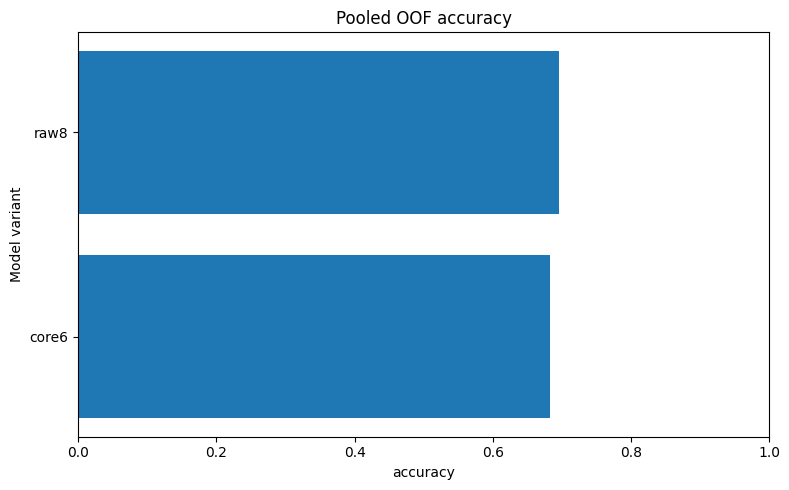

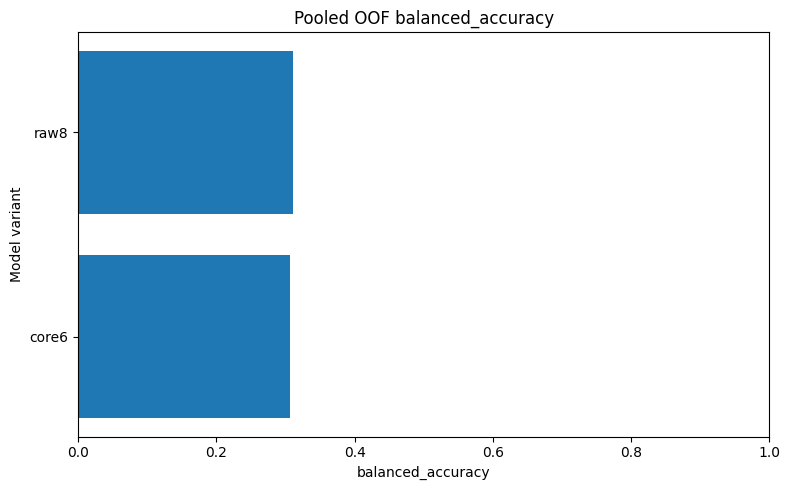

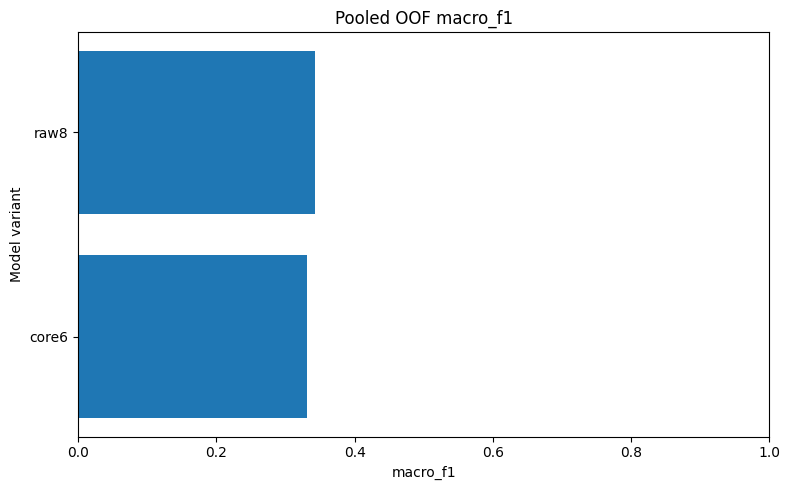

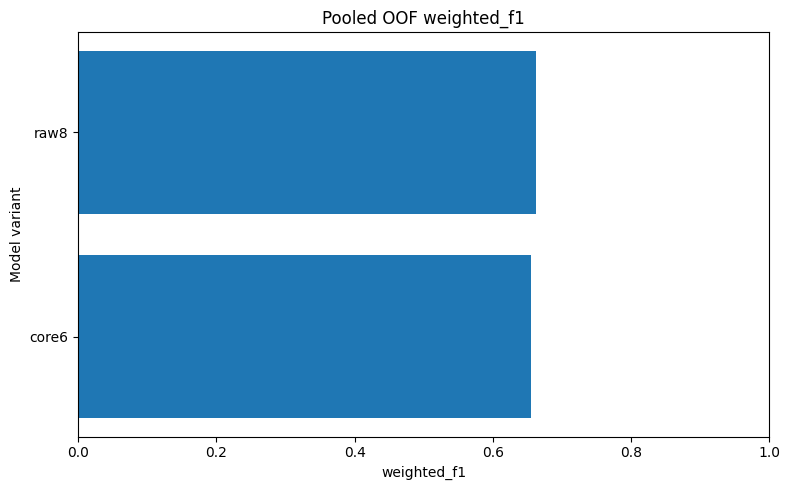

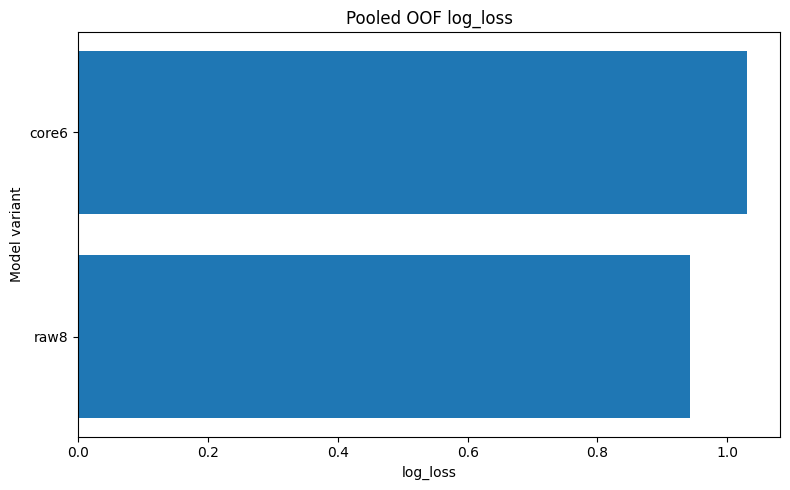

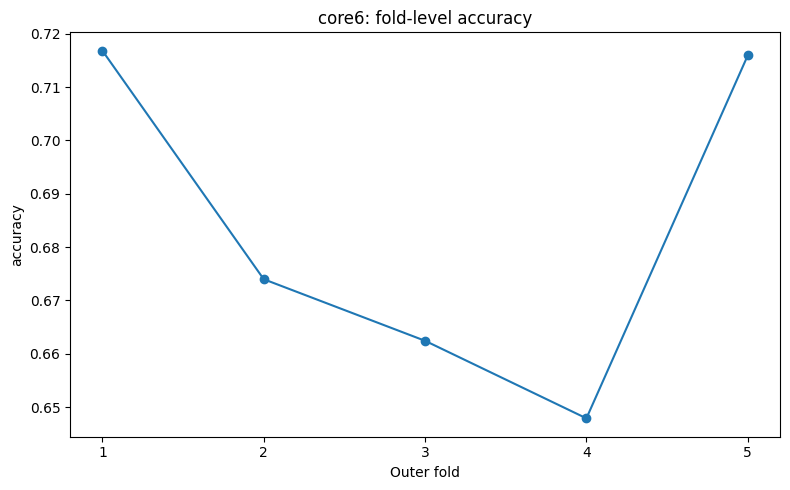

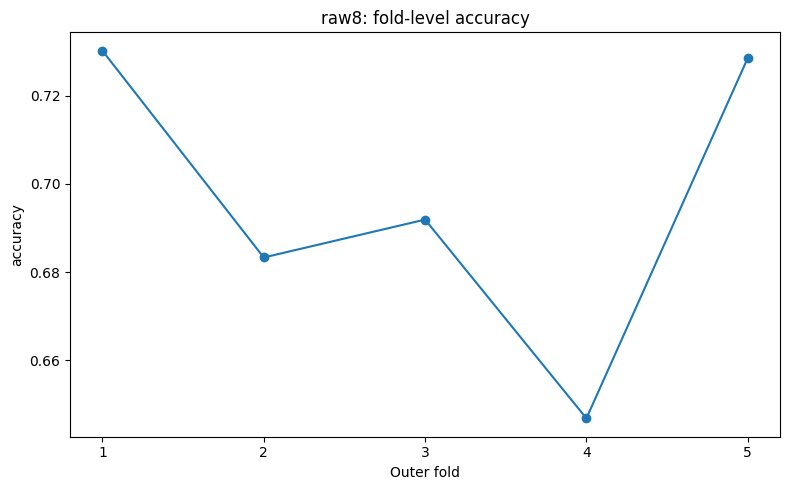

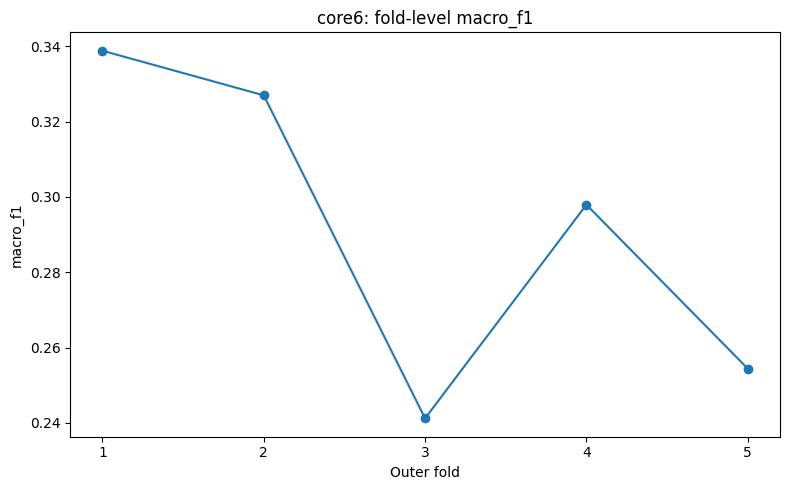

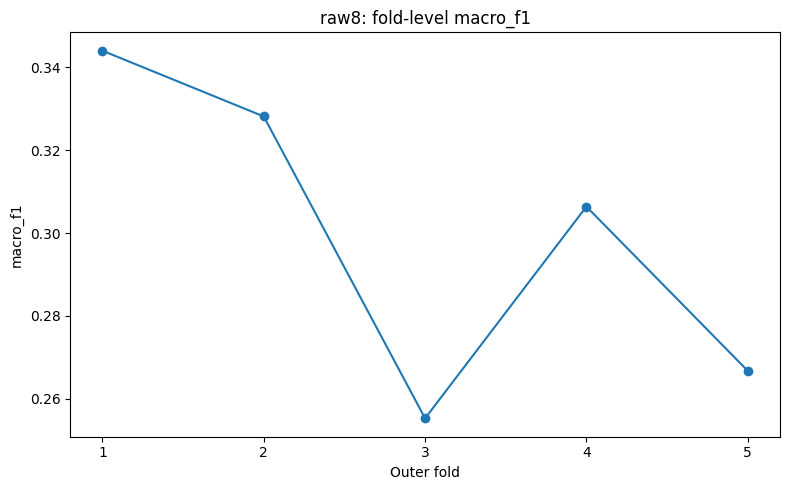

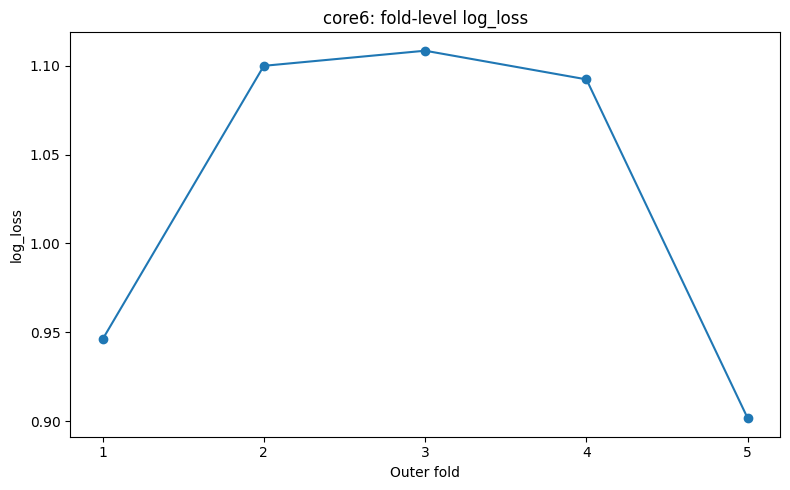

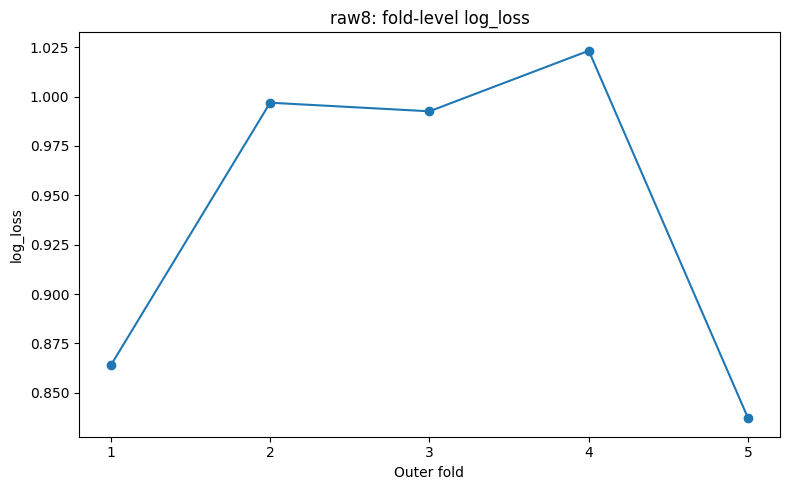

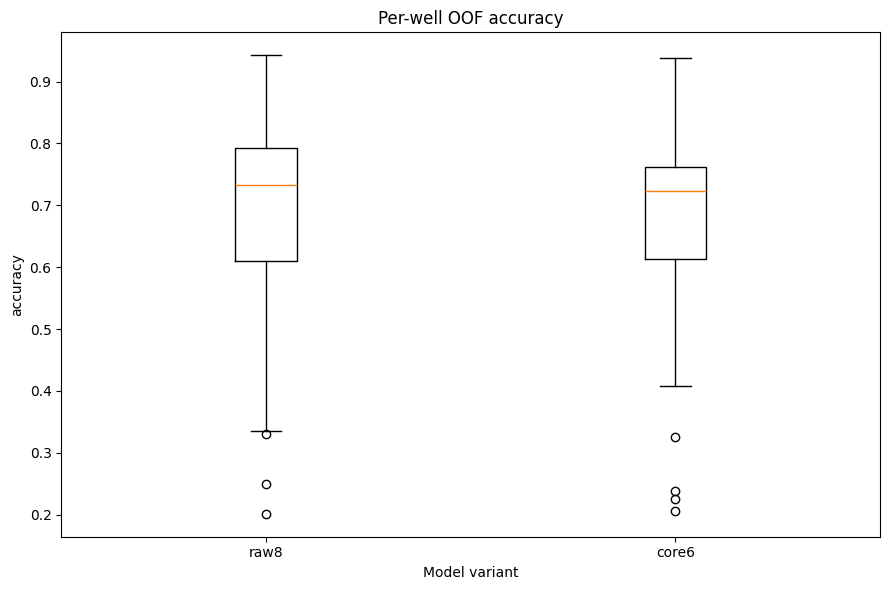

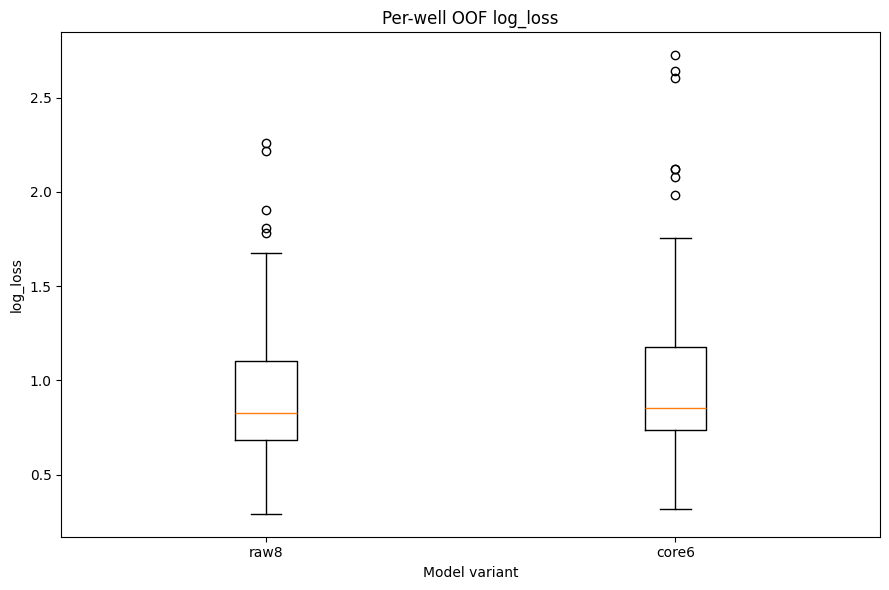

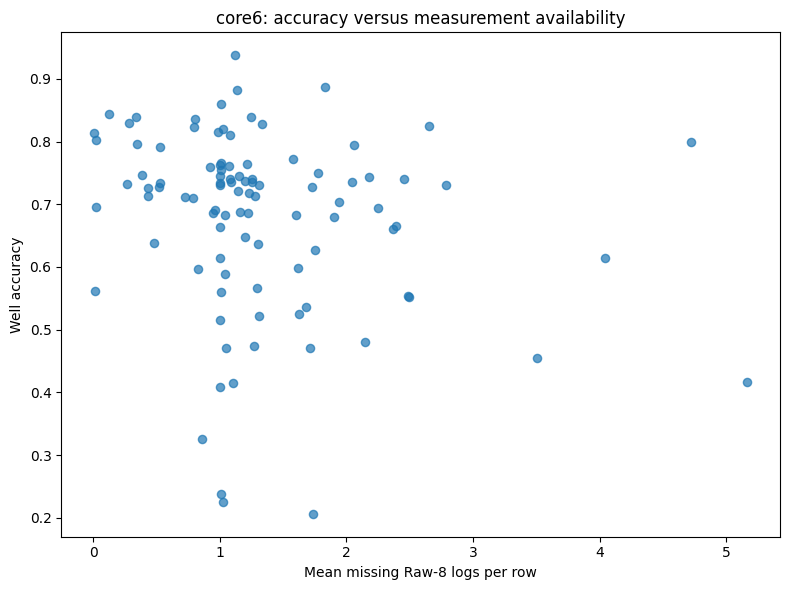

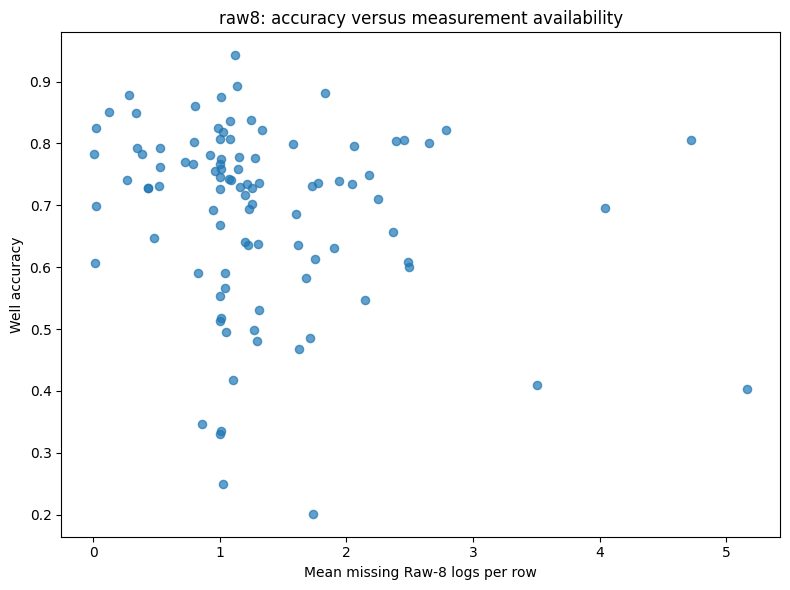

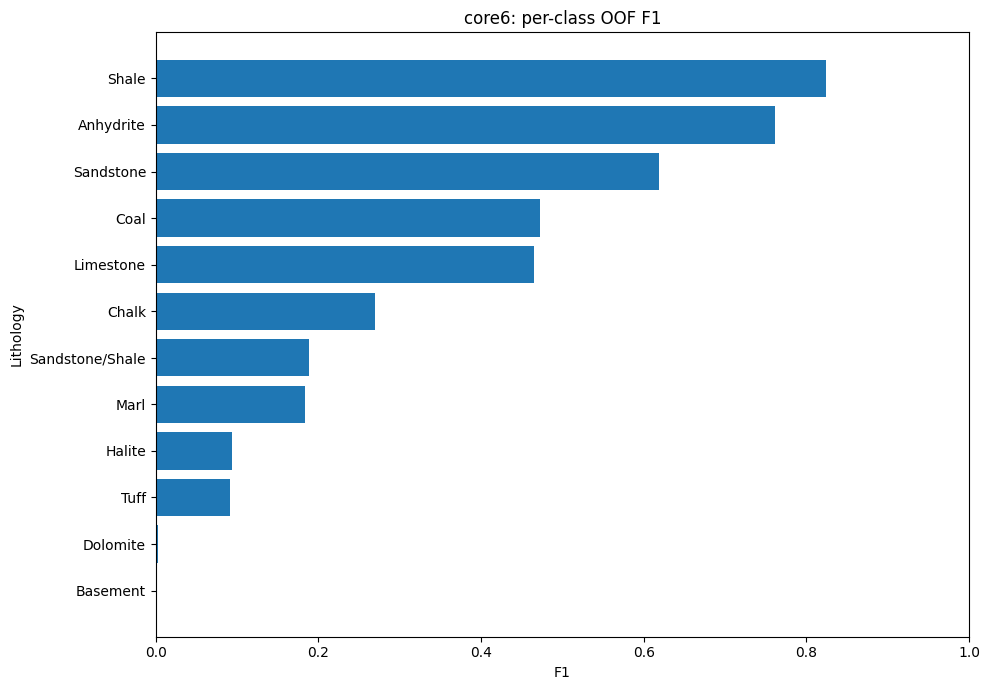

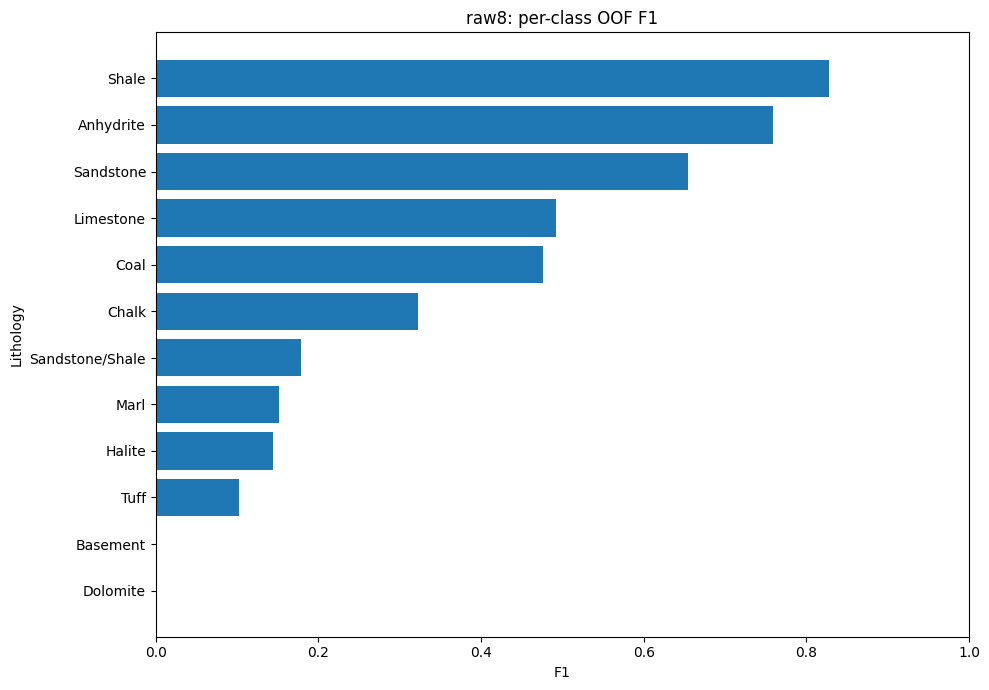

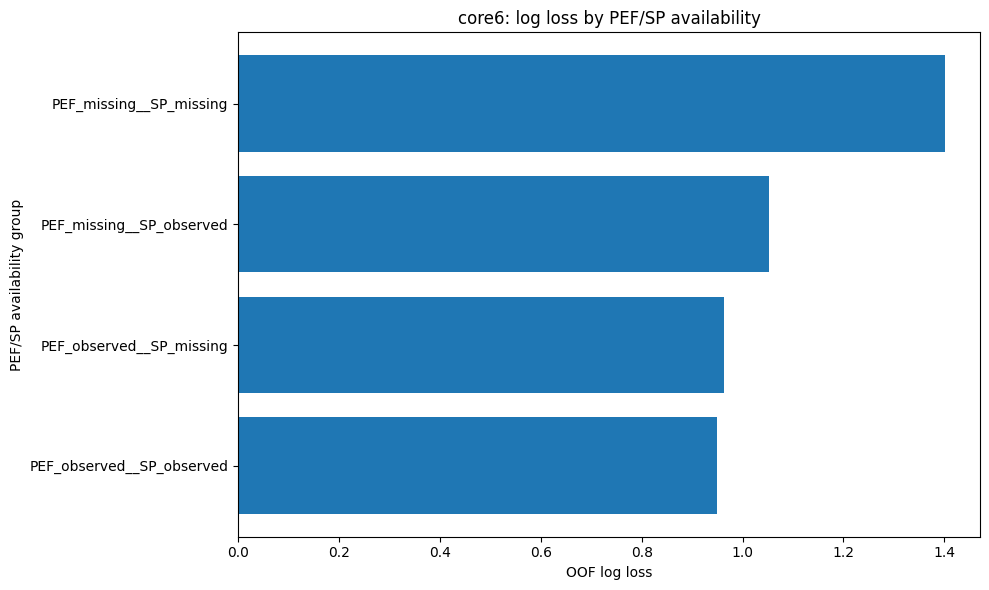

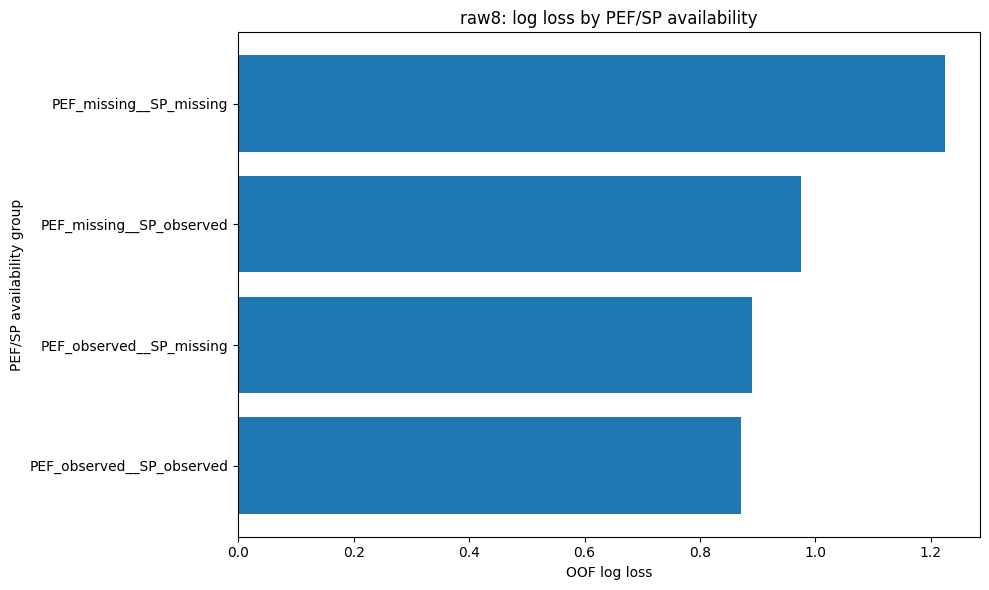

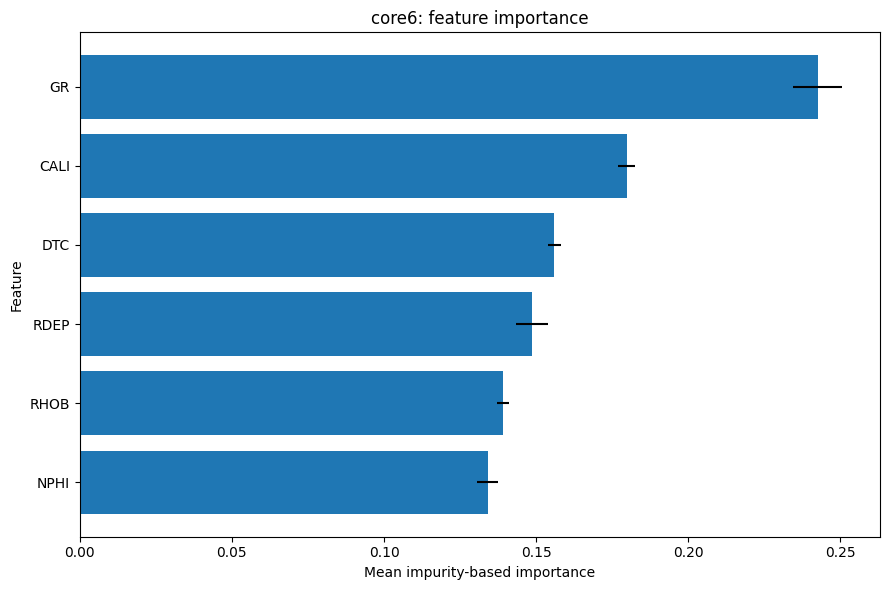

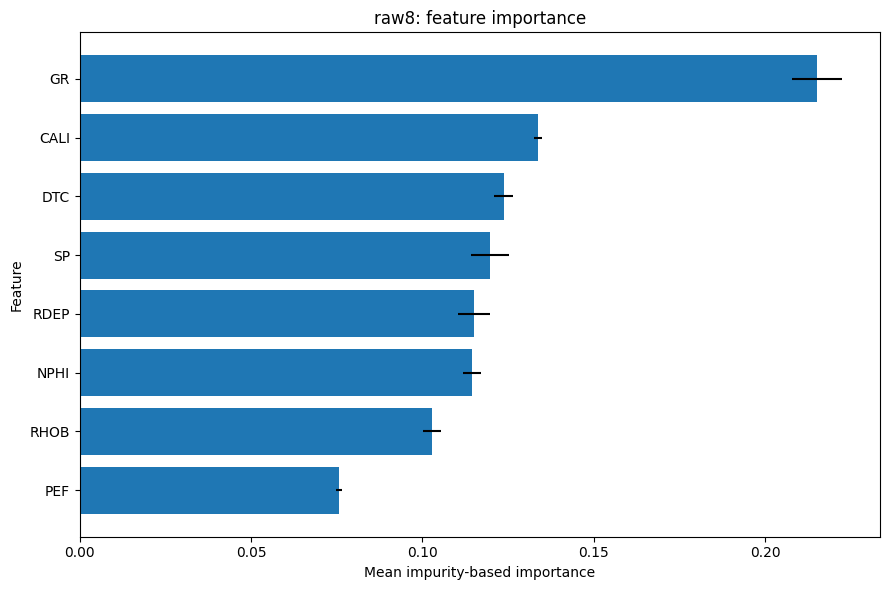

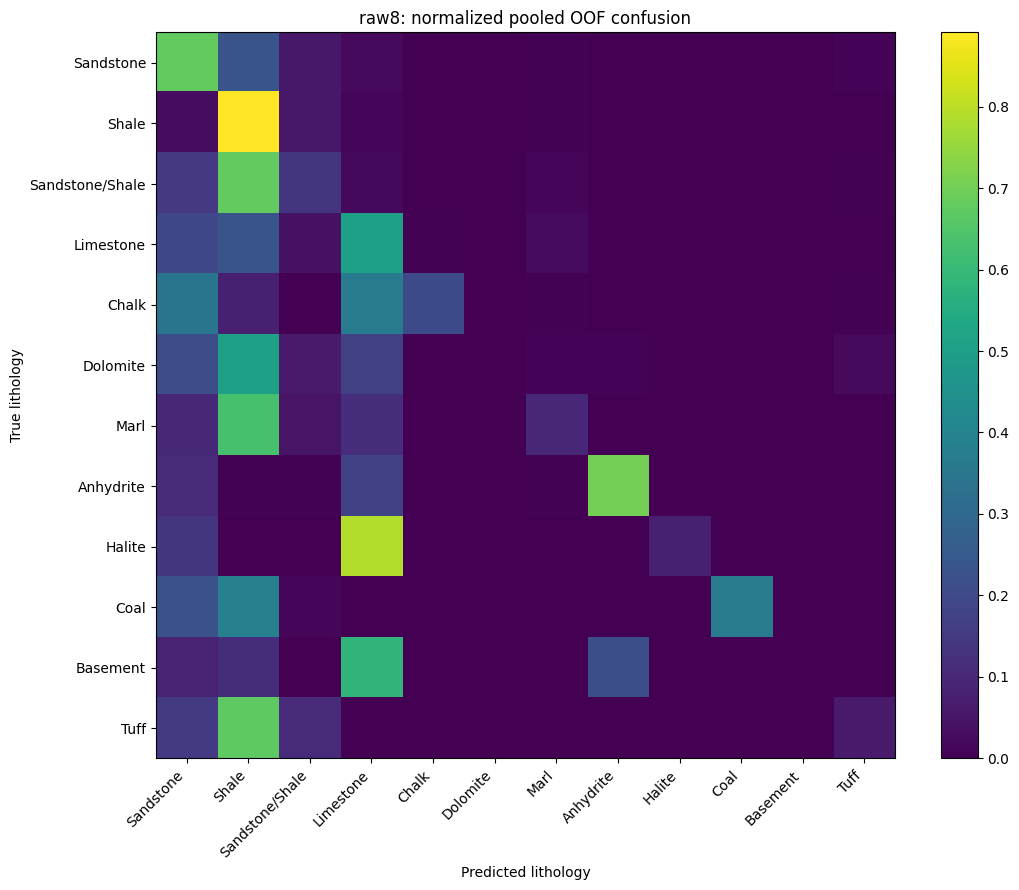

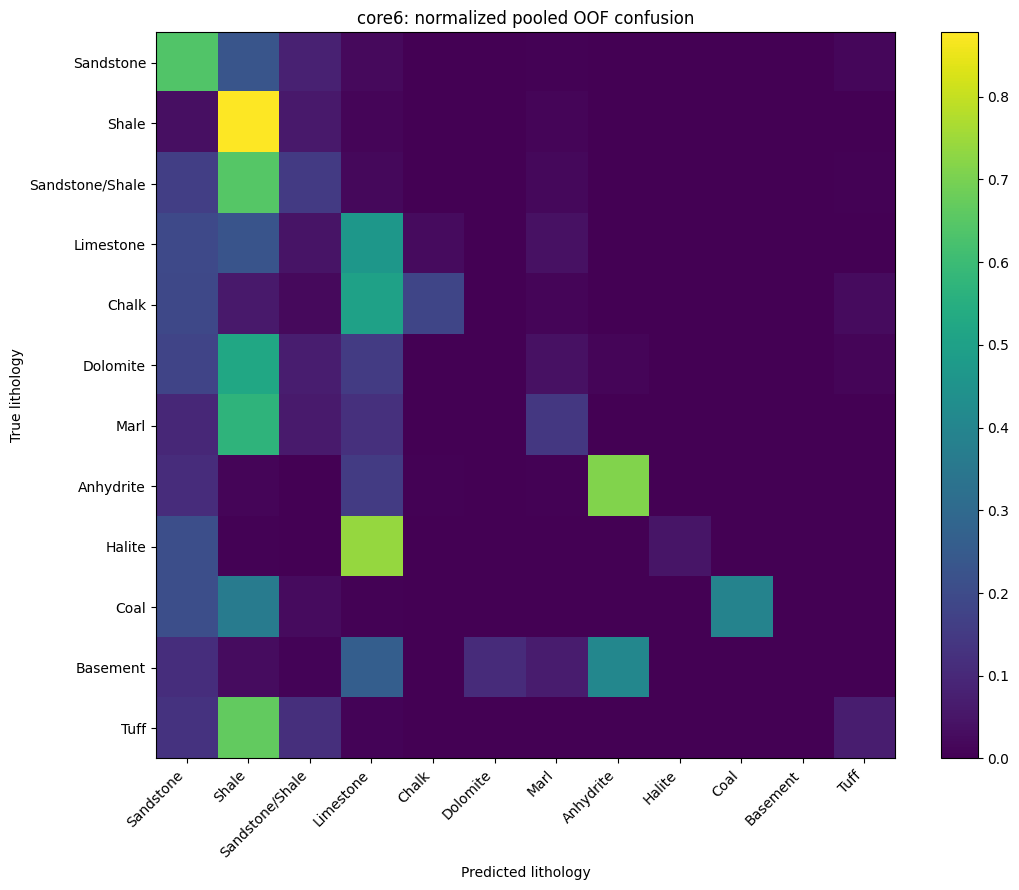

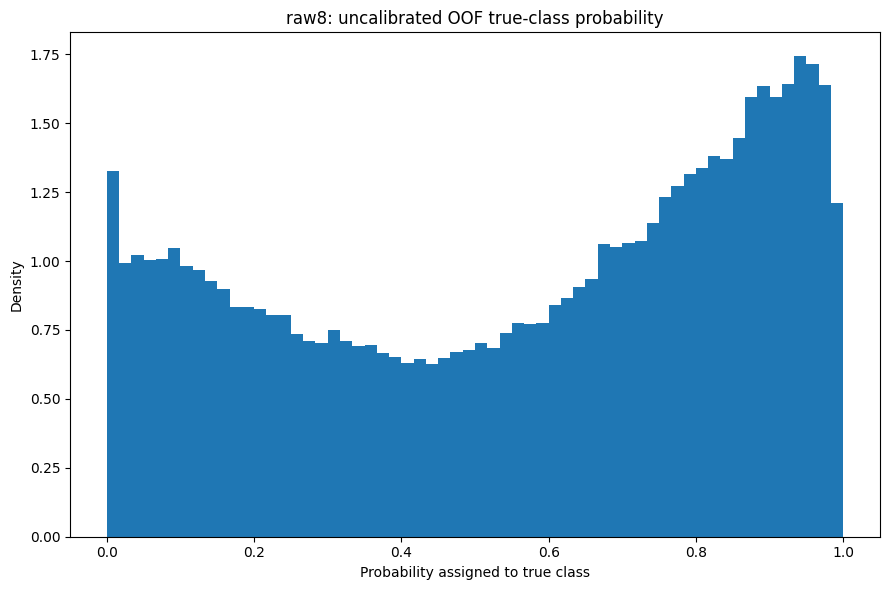

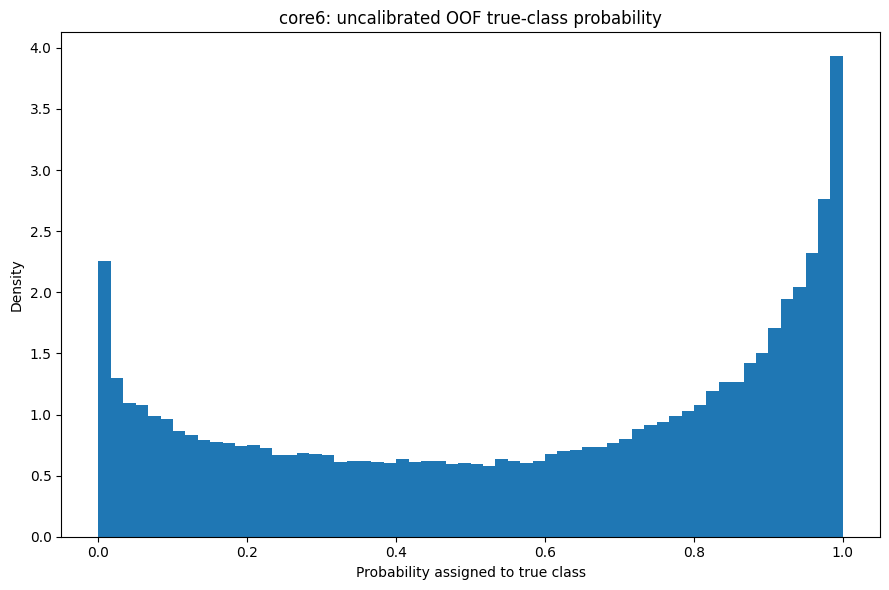

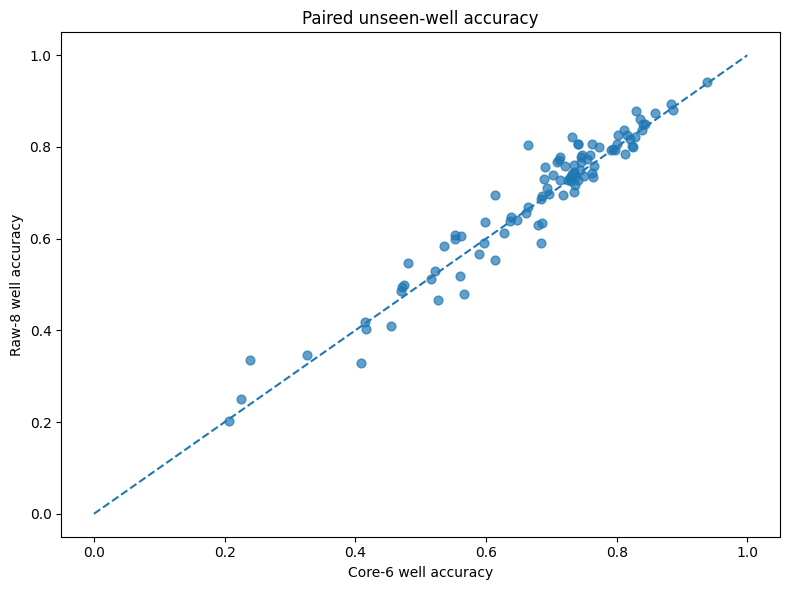

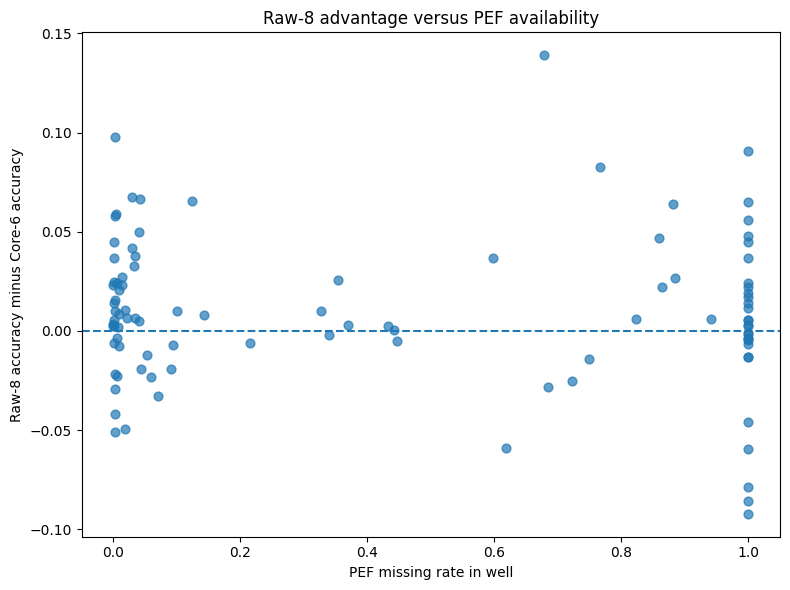

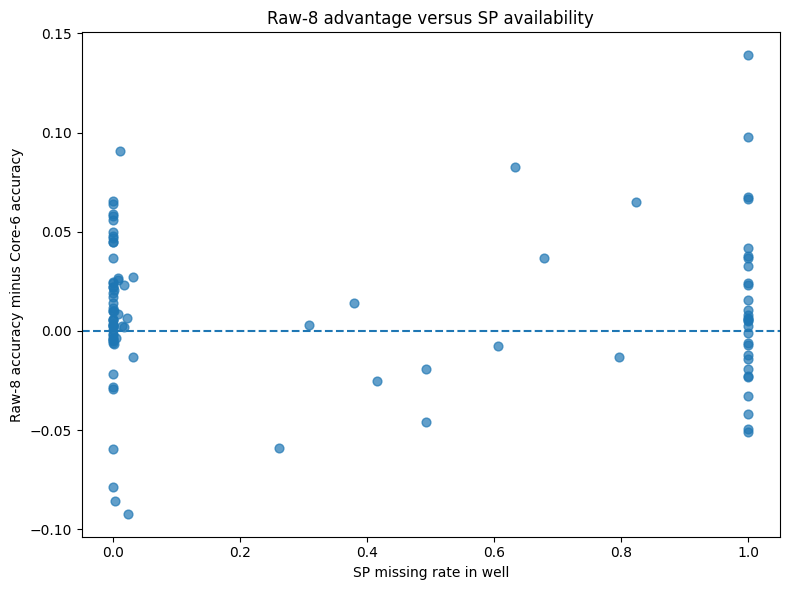

,model_variant,feature,mean_importance,std_importance,minimum_importance,maximum_importance,folds
2,core6,GR,0.242469,0.008008,0.233240,0.251490,5
0,core6,CALI,0.179766,0.002745,0.176041,0.183614,5
1,core6,DTC,0.155945,0.002058,0.153981,0.159199,5
4,core6,RDEP,0.148734,0.005279,0.141958,0.155669,5
5,core6,RHOB,0.139024,0.002033,0.136972,0.142371,5
3,core6,NPHI,0.134062,0.003403,0.129628,0.139120,5
8,raw8,GR,0.215115,0.007300,0.206686,0.222931,5
6,raw8,CALI,0.133712,0.001237,0.131851,0.135281,5
7,raw8,DTC,0.123662,0.002826,0.121718,0.128186,5
13,raw8,SP,0.119609,0.005541,0.112441,0.126514,5


In [13]:
feature_importance_summary_df = (
    feature_importance_df.groupby(["model_variant", "feature"], as_index=False)
    .agg(
        mean_importance=("importance", "mean"),
        std_importance=("importance", "std"),
        minimum_importance=("importance", "min"),
        maximum_importance=("importance", "max"),
        folds=("outer_fold", "nunique"),
    )
    .sort_values(["model_variant", "mean_importance"], ascending=[True, False])
)

def save_current_figure(filename):
    plt.tight_layout()
    plt.savefig(PLOT_DIR / filename, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close()

def plot_confusion(matrix, labels, title, filename):
    plt.figure(figsize=(11, 9))
    image = plt.imshow(matrix, aspect="auto")
    plt.colorbar(image)
    plt.xticks(np.arange(len(labels)), labels, rotation=45, ha="right")
    plt.yticks(np.arange(len(labels)), labels)
    plt.xlabel("Predicted lithology")
    plt.ylabel("True lithology")
    plt.title(title)
    save_current_figure(filename)

for metric_name in ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "log_loss"]:
    plot_df = pooled_metrics_df.sort_values(metric_name)
    plt.figure(figsize=(8, 5))
    plt.barh(plot_df["model_variant"], plot_df[metric_name])
    if metric_name != "log_loss":
        plt.xlim(0, 1)
    plt.xlabel(metric_name)
    plt.ylabel("Model variant")
    plt.title(f"Pooled OOF {metric_name}")
    save_current_figure(f"01_pooled_{metric_name}.png")

for metric_name in ["accuracy", "macro_f1", "log_loss"]:
    for model_variant, variant_df in fold_metrics_df.groupby("model_variant"):
        plt.figure(figsize=(8, 5))
        plt.plot(variant_df["outer_fold"], variant_df[metric_name], marker="o")
        plt.xlabel("Outer fold")
        plt.ylabel(metric_name)
        plt.title(f"{model_variant}: fold-level {metric_name}")
        plt.xticks(sorted(variant_df["outer_fold"].unique()))
        save_current_figure(f"02_fold_{metric_name}_{model_variant}.png")

for metric_name in ["accuracy", "log_loss"]:
    values, labels = [], []
    for model_variant in ACTIVE_MODEL_VARIANTS:
        variant_values = well_metrics_df.loc[
            well_metrics_df["model_variant"] == model_variant,
            metric_name,
        ].dropna().to_numpy()
        if len(variant_values):
            values.append(variant_values)
            labels.append(model_variant)
    plt.figure(figsize=(9, 6))
    plt.boxplot(values, labels=labels, showfliers=True)
    plt.ylabel(metric_name)
    plt.xlabel("Model variant")
    plt.title(f"Per-well OOF {metric_name}")
    save_current_figure(f"03_well_{metric_name}_distribution.png")

for model_variant, variant_wells in well_metrics_df.groupby("model_variant"):
    plt.figure(figsize=(8, 6))
    plt.scatter(
        variant_wells["mean_missing_count_raw8"],
        variant_wells["accuracy"],
        s=35,
        alpha=0.7,
    )
    plt.xlabel("Mean missing Raw-8 logs per row")
    plt.ylabel("Well accuracy")
    plt.title(f"{model_variant}: accuracy versus measurement availability")
    save_current_figure(f"04_accuracy_vs_missing_count_{model_variant}.png")

for model_variant, variant_classes in class_metrics_df.groupby("model_variant"):
    plot_df = variant_classes.sort_values("f1")
    plt.figure(figsize=(10, 7))
    plt.barh(plot_df["class_name"], plot_df["f1"])
    plt.xlim(0, 1)
    plt.xlabel("F1")
    plt.ylabel("Lithology")
    plt.title(f"{model_variant}: per-class OOF F1")
    save_current_figure(f"05_per_class_f1_{model_variant}.png")

availability_df = missingness_metrics_df.loc[
    missingness_metrics_df["grouping_variable"] == "PEF_SP_availability_group"
]
for model_variant, variant_df in availability_df.groupby("model_variant"):
    plot_df = variant_df.sort_values("log_loss")
    plt.figure(figsize=(10, 6))
    plt.barh(plot_df["group_value"], plot_df["log_loss"])
    plt.xlabel("OOF log loss")
    plt.ylabel("PEF/SP availability group")
    plt.title(f"{model_variant}: log loss by PEF/SP availability")
    save_current_figure(f"06_PEF_SP_log_loss_{model_variant}.png")

for model_variant, variant_df in feature_importance_summary_df.groupby("model_variant"):
    plot_df = variant_df.sort_values("mean_importance")
    plt.figure(figsize=(9, 6))
    plt.barh(
        plot_df["feature"],
        plot_df["mean_importance"],
        xerr=plot_df["std_importance"].fillna(0),
    )
    plt.xlabel("Mean impurity-based importance")
    plt.ylabel("Feature")
    plt.title(f"{model_variant}: feature importance")
    save_current_figure(f"07_feature_importance_{model_variant}.png")

labels = [LITHOLOGY_NAMES[int(code)] for code in GLOBAL_CLASS_CODES]
for model_variant, variant_oof in oof_predictions.items():
    matrix = confusion_matrix(
        variant_oof["true_code"],
        variant_oof["predicted_code"],
        labels=GLOBAL_CLASS_CODES,
        normalize="true",
    )
    plot_confusion(
        matrix,
        labels,
        f"{model_variant}: normalized pooled OOF confusion",
        f"08_pooled_confusion_{model_variant}.png",
    )

for model_variant, variant_oof in oof_predictions.items():
    values = variant_oof["true_class_probability"]
    if len(values) > MAX_ROWS_FOR_PLOTS:
        values = values.sample(n=MAX_ROWS_FOR_PLOTS, random_state=RANDOM_STATE)
    plt.figure(figsize=(9, 6))
    plt.hist(values, bins=60, density=True)
    plt.xlabel("Probability assigned to true class")
    plt.ylabel("Density")
    plt.title(f"{model_variant}: uncalibrated OOF true-class probability")
    save_current_figure(f"09_true_probability_{model_variant}.png")

if not paired_well_df.empty:
    plt.figure(figsize=(8, 6))
    plt.scatter(paired_well_df["core6_accuracy"], paired_well_df["raw8_accuracy"], s=40, alpha=0.7)
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("Core-6 well accuracy")
    plt.ylabel("Raw-8 well accuracy")
    plt.title("Paired unseen-well accuracy")
    save_current_figure("10_raw8_vs_core6_well_accuracy.png")

    for missing_feature in ["PEF", "SP"]:
        plt.figure(figsize=(8, 6))
        plt.scatter(
            paired_well_df[f"{missing_feature}_missing_rate"],
            paired_well_df["accuracy_difference_raw8_minus_core6"],
            s=40,
            alpha=0.7,
        )
        plt.axhline(0.0, linestyle="--")
        plt.xlabel(f"{missing_feature} missing rate in well")
        plt.ylabel("Raw-8 accuracy minus Core-6 accuracy")
        plt.title(f"Raw-8 advantage versus {missing_feature} availability")
        save_current_figure(f"11_raw8_advantage_vs_{missing_feature}_missingness.png")

display(feature_importance_summary_df)

> `feature_importances_` یک معیار MDI است. در حضور Featureهای هم‌بسته یا Missingness pattern ممکن است اهمیت را پخش یا منحرف کند. نتیجه اصلی اهمیت Featureها بعدا از Intervention analysis می‌آید، نه فقط این جدول.

# 12. Stage Gate

In [14]:
expected_rows_per_variant = int(
    train_raw["GROUP_FOLD"].isin(ACTIVE_OUTER_FOLDS).sum()
)
expected_wells_per_variant = int(
    train_raw.loc[
        train_raw["GROUP_FOLD"].isin(ACTIVE_OUTER_FOLDS),
        "WELL",
    ].nunique()
)

variant_gates = {}
for model_variant, variant_oof in oof_predictions.items():
    probabilities = variant_oof[PROBABILITY_COLUMNS].to_numpy(dtype=np.float64)
    source_labels = (
        train_raw.set_index("ORIGINAL_ROW_ID")
        .loc[variant_oof["ORIGINAL_ROW_ID"], "LITHOLOGY_CODE"]
        .to_numpy(dtype=np.int64)
    )
    variant_gates[model_variant] = {
        "observed_oof_rows": int(len(variant_oof)),
        "expected_oof_rows": expected_rows_per_variant,
        "oof_row_count_correct": len(variant_oof) == expected_rows_per_variant,
        "oof_row_ids_unique": not variant_oof["ORIGINAL_ROW_ID"].duplicated().any(),
        "observed_wells": int(variant_oof["WELL"].nunique()),
        "expected_wells": expected_wells_per_variant,
        "well_count_correct": variant_oof["WELL"].nunique() == expected_wells_per_variant,
        "outer_fold_count_correct": variant_oof["outer_fold"].nunique() == len(ACTIVE_OUTER_FOLDS),
        "probabilities_finite": bool(np.isfinite(probabilities).all()),
        "probabilities_in_range": bool(
            (probabilities >= -1e-8).all()
            and (probabilities <= 1.0 + 1e-8).all()
        ),
        "probability_rows_sum_to_one": bool(np.allclose(
            probabilities.sum(axis=1), 1.0, rtol=1e-6, atol=1e-6
        )),
        "true_labels_match_source": bool(
            np.array_equal(variant_oof["true_code"].to_numpy(dtype=np.int64), source_labels)
        ),
    }

all_models_exist = bool(
    artifact_manifest_df.loc[
        artifact_manifest_df["artifact_type"] == "random_forest",
        "path",
    ].map(lambda value: Path(value).exists()).all()
)
all_imputers_exist = bool(
    artifact_manifest_df.loc[
        artifact_manifest_df["artifact_type"] == "median_imputer",
        "path",
    ].map(lambda value: Path(value).exists()).all()
)
paired_rows_match = (
    len(paired_rows_df) == expected_rows_per_variant
    if not paired_rows_df.empty
    else False
)

boolean_variant_checks = []
for details in variant_gates.values():
    boolean_variant_checks.extend([
        details["oof_row_count_correct"],
        details["oof_row_ids_unique"],
        details["well_count_correct"],
        details["outer_fold_count_correct"],
        details["probabilities_finite"],
        details["probabilities_in_range"],
        details["probability_rows_sum_to_one"],
        details["true_labels_match_source"],
    ])

STAGE_GATE = {
    "official_test_unused": True,
    "stage_05a_contract_passed": bool(
        stage_05a_gate["overall_raw_feature_contract_passed"]
    ),
    "input_hashes_match_05A": bool(
        CONTRACT_AUDIT["train_hash_matches_05A"]
        and CONTRACT_AUDIT["fold_hash_matches_05A"]
    ),
    "grouped_unseen_well_outer_CV_used": True,
    "all_fold_gates_passed": bool(fold_audit_df["fold_gate_passed"].all()),
    "no_scaling": True,
    "no_feature_engineering": True,
    "no_missingness_indicators_in_model": True,
    "no_hyperparameter_tuning": True,
    "no_calibration": True,
    "same_RF_hyperparameters_for_both_variants": True,
    "all_models_exist": all_models_exist,
    "all_imputers_exist": all_imputers_exist,
    "paired_raw8_core6_rows_match": paired_rows_match,
    "variant_gates": variant_gates,
}
STAGE_GATE["overall_raw_RF_grouped_CV_passed"] = bool(
    STAGE_GATE["official_test_unused"]
    and STAGE_GATE["stage_05a_contract_passed"]
    and STAGE_GATE["input_hashes_match_05A"]
    and STAGE_GATE["grouped_unseen_well_outer_CV_used"]
    and STAGE_GATE["all_fold_gates_passed"]
    and STAGE_GATE["no_scaling"]
    and STAGE_GATE["no_feature_engineering"]
    and STAGE_GATE["no_missingness_indicators_in_model"]
    and STAGE_GATE["no_hyperparameter_tuning"]
    and STAGE_GATE["no_calibration"]
    and STAGE_GATE["same_RF_hyperparameters_for_both_variants"]
    and STAGE_GATE["all_models_exist"]
    and STAGE_GATE["all_imputers_exist"]
    and STAGE_GATE["paired_raw8_core6_rows_match"]
    and all(boolean_variant_checks)
)

print(json.dumps(STAGE_GATE, indent=2))
if not STAGE_GATE["overall_raw_RF_grouped_CV_passed"]:
    raise RuntimeError("05B stage gate failed.")
print("\n✅ Raw-log RF grouped unseen-well CV passed.")

{
  "official_test_unused": true,
  "stage_05a_contract_passed": true,
  "input_hashes_match_05A": true,
  "grouped_unseen_well_outer_CV_used": true,
  "all_fold_gates_passed": true,
  "no_scaling": true,
  "no_feature_engineering": true,
  "no_missingness_indicators_in_model": true,
  "no_hyperparameter_tuning": true,
  "no_calibration": true,
  "same_RF_hyperparameters_for_both_variants": true,
  "all_models_exist": true,
  "all_imputers_exist": true,
  "paired_raw8_core6_rows_match": true,
  "variant_gates": {
    "raw8": {
      "observed_oof_rows": 1170511,
      "expected_oof_rows": 1170511,
      "oof_row_count_correct": true,
      "oof_row_ids_unique": true,
      "observed_wells": 98,
      "expected_wells": 98,
      "well_count_correct": true,
      "outer_fold_count_correct": true,
      "probabilities_finite": true,
      "probabilities_in_range": true,
      "probability_rows_sum_to_one": true,
      "true_labels_match_source": true
    },
    "core6": {
      "observed_

# 13. ذخیره خروجی‌ها

In [15]:
cleaning_audit.to_csv(OUTPUT_DIR / "00_cleaning_audit.csv", index=False)
global_class_support.to_csv(OUTPUT_DIR / "01_global_class_support.csv", index=False)
fold_metrics_df.to_csv(OUTPUT_DIR / "02_outer_fold_metrics.csv", index=False)
pooled_metrics_df.to_csv(OUTPUT_DIR / "03_pooled_oof_metrics.csv", index=False)
well_metrics_df.to_csv(OUTPUT_DIR / "04_per_well_metrics.csv", index=False)
well_balanced_metrics_df.to_csv(OUTPUT_DIR / "05_well_balanced_metrics.csv", index=False)
class_metrics_df.to_csv(OUTPUT_DIR / "06_per_class_metrics.csv", index=False)
missingness_metrics_df.to_csv(OUTPUT_DIR / "07_missingness_stratified_metrics.csv", index=False)
imputer_medians_df.to_csv(OUTPUT_DIR / "08_fold_imputer_medians.csv", index=False)
feature_importance_df.to_csv(OUTPUT_DIR / "09_fold_feature_importances.csv", index=False)
feature_importance_summary_df.to_csv(OUTPUT_DIR / "10_feature_importance_summary.csv", index=False)
fold_audit_df.to_csv(OUTPUT_DIR / "11_fold_audit.csv", index=False)
artifact_manifest_df.to_csv(OUTPUT_DIR / "12_artifact_manifest.csv", index=False)

if not paired_rows_df.empty:
    paired_rows_df.to_parquet(
        OUTPUT_DIR / "13_raw8_vs_core6_paired_rows.parquet",
        index=False,
    )
    paired_summary_df.to_csv(
        OUTPUT_DIR / "14_raw8_vs_core6_paired_summary.csv",
        index=False,
    )
    paired_well_df.to_csv(
        OUTPUT_DIR / "15_raw8_vs_core6_per_well_comparison.csv",
        index=False,
    )

for model_variant, variant_oof in oof_predictions.items():
    variant_oof.to_parquet(
        OUTPUT_DIR / f"16_OOF_predictions_{model_variant}.parquet",
        index=False,
    )

with open(OUTPUT_DIR / "17_stage_gate.json", "w", encoding="utf-8") as file:
    json.dump(STAGE_GATE, file, ensure_ascii=False, indent=2)

RUN_CONFIGURATION = {
    "stage": "05B_raw_log_RF_grouped_well_CV",
    "run_mode": RUN_MODE,
    "official_test_used": False,
    "outer_folds": ACTIVE_OUTER_FOLDS,
    "model_variants": MODEL_VARIANTS,
    "active_model_variants": ACTIVE_MODEL_VARIANTS,
    "rf_hyperparameters": RF_HYPERPARAMETERS,
    "preprocessing": {
        "sentinel_values": SENTINEL_VALUES,
        "positive_only_features": sorted(POSITIVE_ONLY_FEATURES),
        "imputation": "feature-wise median fitted on outer-training rows only",
        "scaling": False,
        "feature_engineering": False,
        "missingness_indicators_in_model": False,
    },
    "probability_status": "raw uncalibrated OOF probabilities",
    "grouping_column": "WELL",
    "input_hashes": current_hashes,
    "next_stage": "05C_raw_RF_strict_nested_temperature_calibration",
    "downstream_use": [
        "05C calibration",
        "06A raw-RF class-transport interventions",
    ],
}
with open(OUTPUT_DIR / "18_run_configuration.json", "w", encoding="utf-8") as file:
    json.dump(RUN_CONFIGURATION, file, ensure_ascii=False, indent=2)

ENVIRONMENT = {
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
}
with open(OUTPUT_DIR / "19_environment.json", "w", encoding="utf-8") as file:
    json.dump(ENVIRONMENT, file, ensure_ascii=False, indent=2)

print("Outputs:", OUTPUT_DIR)
print("Models:", MODEL_DIR)
print("Plots:", PLOT_DIR)

Outputs: ${STRATASHIFT_ARTIFACT_ROOT}/05B_raw_log_RF_grouped_well_CV/full
Models: ${STRATASHIFT_ARTIFACT_ROOT}/05B_raw_log_RF_grouped_well_CV/full/models
Plots: ${STRATASHIFT_ARTIFACT_ROOT}/05B_raw_log_RF_grouped_well_CV/full/plots


# 14. فایل‌هایی که بعد از Pilot باید ارسال شوند

از مسیر:

```text
${STRATASHIFT_ARTIFACT_ROOT}/
05B_raw_log_RF_grouped_well_CV/pilot
```

این فایل‌ها را ارسال کن:

```text
02_outer_fold_metrics.csv
03_pooled_oof_metrics.csv
04_per_well_metrics.csv
05_well_balanced_metrics.csv
06_per_class_metrics.csv
07_missingness_stratified_metrics.csv
08_fold_imputer_medians.csv
10_feature_importance_summary.csv
11_fold_audit.csv
14_raw8_vs_core6_paired_summary.csv
15_raw8_vs_core6_per_well_comparison.csv
17_stage_gate.json
18_run_configuration.json
```

Plotهای مهم:

```text
02_fold_accuracy_raw8.png
02_fold_log_loss_raw8.png
03_well_accuracy_distribution.png
04_accuracy_vs_missing_count_raw8.png
05_per_class_f1_raw8.png
06_PEF_SP_log_loss_raw8.png
07_feature_importance_raw8.png
08_pooled_confusion_raw8.png
10_raw8_vs_core6_well_accuracy.png
11_raw8_advantage_vs_PEF_missingness.png
```

پس از پاس‌شدن Pilot:

```python
RUN_MODE = "full"
```

و سپس:

```text
Restart Kernel
Run All
```

مرحله بعدی `05C` است و Probabilityهای خام این Notebook را با Strict nested grouped temperature scaling کالیبره می‌کند.